# 9. Procedural CPTAC validation partitions

This notebook mirrors the procedural analyses from `procedural_ccle.ipynb`, but runs them on the external validation metrics produced in `8.prot_model_val.ipynb`.

The validation datasets are:

- `itraq`
- `tmt`
- `labelfree`

The core procedural question is the same as in the CCLE notebook:

> Which proteins are already good under same-gene/proxy baselines, which are rescued by ENet, which are rescued by XGB, and which remaining proteins are rescued by scTranslator?

Main base cascade:

```text
same-gene proxy/baseline -> ENet -> XGB -> Still not good
```

Optional final rescue cascade:

```text
same-gene proxy/baseline -> ENet -> XGB -> scTranslator -> Still not good after scTranslator
```

Inputs are expected in `../results_comparison_all_models/`, matching notebook `8.prot_model_val.ipynb`:

- `eval_metrics_by_protein.csv`
- optionally `eval_metrics_by_tissue.csv`
- optionally `eval_predictions_long.parquet` or `eval_predictions_long.csv`
- optionally scTranslator prediction files such as `itraq/predictions_10K.npz`, `tmt/predictions_10K.npz`, and `labelfree/predictions_10K.npz`


In [1]:
from pathlib import Path
import sys

# Make the adjacent src/ package importable when this notebook is run from the notebooks folder.
NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import src.utils_val as uv

In [2]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 80)


## 1. Configuration and data loading

This reads the same validation result files used by notebook `8.prot_model_val.ipynb`.

Set `SAVE_OUTPUTS = True` to save tables and figures.

In [3]:
OUTPUT_DIR = Path("../results_comparison_all_models")
METRICS_PROTEIN_CSV = OUTPUT_DIR / "eval_metrics_by_protein.csv"
METRICS_TISSUE_CSV = OUTPUT_DIR / "eval_metrics_by_tissue.csv"
PREDICTIONS_PARQUET = OUTPUT_DIR / "eval_predictions_long.parquet"
PREDICTIONS_CSV = OUTPUT_DIR / "eval_predictions_long.csv"

EXPORT_TABLE_DIR = OUTPUT_DIR / "procedural_cptac_tables"
FIGURE_DIR = OUTPUT_DIR / "procedural_cptac_figures"
SAVE_OUTPUTS = False

if SAVE_OUTPUTS:
    EXPORT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

REQUESTED_DATASETS = ["itraq", "tmt", "labelfree"]

PEARSON_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]
PEARSON_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]

COSINE_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]
COSINE_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]

# MSE is scale-dependent. These absolute thresholds are useful when validation
# targets are on a comparable transformed scale. Edit if needed.
MSE_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 1.05, 0.05)]

# Also used for a percentile-based MSE threshold table.
MSE_PERCENTILE_THRESHOLDS = [10, 25, 50, 75]

# Exclude exact k50 and k500 runs, keeping k5000. This matches notebook 8.
SKIP_K_PATTERN = r"(?<![A-Za-z0-9])k(?:50|500)(?![A-Za-z0-9])"

# Optional scTranslator re-evaluation from saved prediction matrices.
# If scTranslator rows already exist in eval_metrics_by_protein.csv, they are used directly.
# If not, this section can compute scTranslator 10K metrics from predictions_10K files.
RUN_SCTRANSLATOR_REEVALUATION = True
SCTRANSLATOR_VARIANT = "10K"
TARGET_ENET_RUN_LABEL = "res_enet_zbig | zscore | fast | k5000"

if not METRICS_PROTEIN_CSV.exists():
    raise FileNotFoundError(
        f"Missing {METRICS_PROTEIN_CSV}. Run 7/8 validation notebooks first."
    )

metrics_by_protein_raw = pd.read_csv(METRICS_PROTEIN_CSV)
metrics_by_tissue = pd.read_csv(METRICS_TISSUE_CSV) if METRICS_TISSUE_CSV.exists() else pd.DataFrame()

print("Loaded protein metrics:", metrics_by_protein_raw.shape)
print("Raw datasets:", sorted(metrics_by_protein_raw["dataset"].dropna().astype(str).unique()))
print("Raw run labels:", metrics_by_protein_raw["run_label"].nunique())
display(metrics_by_protein_raw.head())

uv.configure_runtime_globals(
    OUTPUT_DIR=OUTPUT_DIR,
    PREDICTIONS_PARQUET=PREDICTIONS_PARQUET,
    PREDICTIONS_CSV=PREDICTIONS_CSV,
    METRICS_PROTEIN_CSV=METRICS_PROTEIN_CSV,
    METRICS_TISSUE_CSV=METRICS_TISSUE_CSV,
    EXPORT_TABLE_DIR=EXPORT_TABLE_DIR,
    FIGURE_DIR=FIGURE_DIR,
    SAVE_OUTPUTS=SAVE_OUTPUTS,
    TARGET_ENET_RUN_LABEL=TARGET_ENET_RUN_LABEL,
)


Loaded protein metrics: (64881, 16)
Raw datasets: ['LabelFree', 'TMT', 'iTRAQ']
Raw run labels: 15


,dataset,protein,source_folder,model_family,normalization,grid_preset,select_k,run_label,h5_path,test_mse,test_pearson_corr,test_cosine_similarity,n_test_used,selected_feature_count,missing_feature_count,missing_feature_fraction
0,LabelFree,A2M,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,4.436586,-0.204794,-0.184042,360,5000,1820,NaN
1,LabelFree,AARS2,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAR...,1.369630,0.427378,0.408251,360,5000,2115,NaN
2,LabelFree,AASDHPPT,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAS...,1.778279,-0.561815,-0.540904,360,5000,1567,NaN
3,LabelFree,ABCB7,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\ABC...,1.235986,0.493335,0.463066,360,5000,2066,NaN
4,LabelFree,ABCD3,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\ABC...,0.375855,0.471613,0.465762,360,5000,1851,NaN


{'OUTPUT_DIR': WindowsPath('../results_comparison_all_models'),
 'PREDICTIONS_PARQUET': WindowsPath('../results_comparison_all_models/eval_predictions_long.parquet'),
 'PREDICTIONS_CSV': WindowsPath('../results_comparison_all_models/eval_predictions_long.csv'),
 'METRICS_PROTEIN_CSV': WindowsPath('../results_comparison_all_models/eval_metrics_by_protein.csv'),
 'METRICS_TISSUE_CSV': WindowsPath('../results_comparison_all_models/eval_metrics_by_tissue.csv'),
 'EXPORT_TABLE_DIR': WindowsPath('../results_comparison_all_models/procedural_cptac_tables'),
 'FIGURE_DIR': WindowsPath('../results_comparison_all_models/procedural_cptac_figures'),
 'SAVE_OUTPUTS': False,
 'TARGET_ENET_RUN_LABEL': 'res_enet_zbig | zscore | fast | k5000'}

## 2. Normalization, labels, and helper functions

In [4]:
from src.utils_val import (
    _index_by_protein,
    best_per_protein,
    dataset_display_name,
    first_existing_column,
    fmt_num,
    infer_stage_from_run_label,
    is_enet_label,
    is_proxy_label,
    is_sctranslator_label,
    is_xgb_label,
    normalize_name,
    require_columns,
    safe_metric,
)

## 3. Prepare validation metrics for iTRAQ, TMT, and LabelFree

This filters to the requested validation datasets and excludes exact `k50`/`k500` runs, matching notebook 8.

In [5]:
require_columns(
    metrics_by_protein_raw,
    ["dataset", "run_label", "protein", "test_pearson_corr", "test_cosine_similarity", "test_mse"],
    "metrics_by_protein_raw",
)

metrics_by_protein = metrics_by_protein_raw.copy()
metrics_by_protein["dataset_key"] = metrics_by_protein["dataset"].map(normalize_name)
metrics_by_protein["requested_dataset"] = metrics_by_protein["dataset_key"].isin(
    [normalize_name(x) for x in REQUESTED_DATASETS]
)

skip_mask = (
    metrics_by_protein["run_label"]
    .astype(str)
    .str.contains(SKIP_K_PATTERN, case=False, regex=True, na=False)
)

metrics_partition = metrics_by_protein.loc[
    metrics_by_protein["requested_dataset"] & ~skip_mask
].copy()

metrics_partition["stage"] = metrics_partition["run_label"].map(infer_stage_from_run_label)
metrics_partition["dataset_display"] = metrics_partition["dataset_key"].map(dataset_display_name)
metrics_partition["protein"] = metrics_partition["protein"].astype(str)
metrics_partition["run_label"] = metrics_partition["run_label"].astype(str)

requested_found = (
    metrics_partition[["dataset_key", "dataset_display"]]
    .drop_duplicates()
    .sort_values("dataset_key")
    .reset_index(drop=True)
)

print(
    f"Using {len(metrics_partition):,} rows after keeping requested datasets "
    f"and excluding {int(skip_mask.sum()):,} exact k50/k500 rows."
)
print("Datasets retained:")
display(requested_found)

print("Run/stage overview:")
overview = (
    metrics_partition
    .groupby(["dataset_display", "stage", "run_label"], dropna=False)
    .agg(
        rows=("protein", "size"),
        proteins=("protein", "nunique"),
        median_pearson=("test_pearson_corr", "median"),
        median_cosine=("test_cosine_similarity", "median"),
        median_mse=("test_mse", "median"),
    )
    .reset_index()
    .sort_values(["dataset_display", "stage", "median_pearson"], ascending=[True, True, False])
)
display(overview)

if SAVE_OUTPUTS:
    overview.to_csv(EXPORT_TABLE_DIR / "validation_run_stage_overview.csv", index=False)


Using 64,650 rows after keeping requested datasets and excluding 231 exact k50/k500 rows.
Datasets retained:


,dataset_key,dataset_display
0,itraq,iTRAQ
1,labelfree,LabelFree
2,tmt,TMT


Run/stage overview:


,dataset_display,stage,run_label,rows,proteins,median_pearson,median_cosine,median_mse
2,LabelFree,ENet,results_enet | ranking | fast | k2000,2155,2155,0.113368,5.349470e-02,3.361032e+07
4,LabelFree,ENet,results_enet | zscore | fast | k2000,2155,2155,0.103802,9.669994e-02,1.030591e+00
0,LabelFree,ENet,res_enet_zbig | zscore | fast | k5000,2155,2155,0.099160,9.242556e-02,1.057716e+00
1,LabelFree,ENet,results_enet | none | fast | k2000,2155,2155,0.087016,1.033444e-02,2.007185e+00
3,LabelFree,ENet,results_enet | unknown | fast | k2000,2155,2155,0.085826,1.790948e-02,2.536887e+00
9,LabelFree,XGB,results_xgb | zscore | fast | k2000,2155,2155,0.100798,5.271784e-02,1.156633e+00
5,LabelFree,XGB,res_xgb_zbig | zscore | current | k5000,2155,2155,0.099510,5.179310e-02,1.155184e+00
7,LabelFree,XGB,results_xgb | qbin50 | fast | k2000,2155,2155,0.087238,4.647627e-02,1.181905e+00
8,LabelFree,XGB,results_xgb | rank | fast | k2000,2155,2155,0.080376,4.657988e-02,1.194250e+00
6,LabelFree,XGB,results_xgb | none | fast | k2000,2155,2155,-0.007734,1.516288e-02,1.081109e+00


## 4. Best-per-family tables

For each validation dataset, this chooses the best row per protein within each model family/stage:

- proxy/baseline: best of same-gene/proxy/baseline rows
- ENet: best ENet row
- XGB: best XGB row
- scTranslator: best scTranslator row, if available or computed later

Separate best tables are made for Pearson, cosine, and MSE.

In [6]:
from src.utils_val import get_dataset_metrics, make_family_best_tables_for_dataset

BASE_STAGES = ["Proxy Pearson", "Proxy Spearman", "Proxy baseline", "ENet", "XGB"]
PROXY_STAGES = ["Proxy Pearson", "Proxy Spearman", "Proxy baseline"]
SC_STAGES = ["scTranslator 2M", "scTranslator 160K", "scTranslator 10K", "scTranslator"]

CASCADE_ORDER_BASE = [
    "Proxy Pearson",
    "Proxy Spearman",
    "Proxy baseline",
    "ENet",
    "XGB",
    "Still not good",
]

CASCADE_ORDER_WITH_SC = [
    "Proxy Pearson",
    "Proxy Spearman",
    "Proxy baseline",
    "ENet",
    "XGB",
    "scTranslator 2M",
    "scTranslator 160K",
    "scTranslator 10K",
    "scTranslator",
    "Still not good after scTranslator",
]

MSE_WINNER_ORDER = [
    "Proxy Pearson lowest MSE",
    "Proxy Spearman lowest MSE",
    "Proxy baseline lowest MSE",
    "ENet lowest MSE",
    "XGB lowest MSE",
    "No valid MSE",
]

MSE_IMPROVEMENT_ORDER = [
    "Proxy retained / no lower MSE found",
    "ENet improves over proxy",
    "XGB improves over previous best",
    "ENet first valid MSE",
    "XGB first valid MSE",
    "No valid comparison",
]

COLOR_MAP = {
    "Proxy Pearson": "#4C78A8",
    "Proxy Spearman": "#72B7B2",
    "Proxy baseline": "#A0CBE8",
    "ENet": "#54A24B",
    "XGB": "#F58518",
    "scTranslator 2M": "#B279A2",
    "scTranslator 160K": "#9D755D",
    "scTranslator 10K": "#BAB0AC",
    "scTranslator": "#8F8F8F",
    "Still not good": "#E45756",
    "Still not good after scTranslator": "#E45756",
    "Proxy Pearson lowest MSE": "#4C78A8",
    "Proxy Spearman lowest MSE": "#72B7B2",
    "Proxy baseline lowest MSE": "#A0CBE8",
    "ENet lowest MSE": "#54A24B",
    "XGB lowest MSE": "#F58518",
    "No valid MSE": "#E45756",
    "Proxy retained / no lower MSE found": "#4C78A8",
    "ENet improves over proxy": "#54A24B",
    "XGB improves over previous best": "#F58518",
    "ENet first valid MSE": "#8CD17D",
    "XGB first valid MSE": "#FFBE7D",
    "No valid comparison": "#E45756",
}






uv.configure_runtime_globals(
    metrics_partition=metrics_partition,
    BASE_STAGES=BASE_STAGES,
    PROXY_STAGES=PROXY_STAGES,
    SC_STAGES=SC_STAGES,
    COLOR_MAP=COLOR_MAP,
    SAVE_OUTPUTS=SAVE_OUTPUTS,
    FIGURE_DIR=FIGURE_DIR,
    EXPORT_TABLE_DIR=EXPORT_TABLE_DIR,
)

DATASET_KEYS = [normalize_name(x) for x in REQUESTED_DATASETS]
family_tables = {
    key: make_family_best_tables_for_dataset(key)
    for key in DATASET_KEYS
    if len(get_dataset_metrics(key)) > 0
}

coverage_rows = []
for key, tables in family_tables.items():
    coverage_rows.append({
        "dataset": tables["dataset_display"],
        "protein_universe": len(tables["protein_universe"]),
        "proxy_pearson_valid": tables["proxy_best_pearson"]["protein"].nunique() if len(tables["proxy_best_pearson"]) else 0,
        "enet_pearson_valid": tables["enet_best_pearson"]["protein"].nunique() if len(tables["enet_best_pearson"]) else 0,
        "xgb_pearson_valid": tables["xgb_best_pearson"]["protein"].nunique() if len(tables["xgb_best_pearson"]) else 0,
        "proxy_mse_valid": tables["proxy_best_mse"]["protein"].nunique() if len(tables["proxy_best_mse"]) else 0,
        "enet_mse_valid": tables["enet_best_mse"]["protein"].nunique() if len(tables["enet_best_mse"]) else 0,
        "xgb_mse_valid": tables["xgb_best_mse"]["protein"].nunique() if len(tables["xgb_best_mse"]) else 0,
        "sc_pearson_valid_current": tables["sc_best_pearson"]["protein"].nunique() if len(tables["sc_best_pearson"]) else 0,
    })

coverage = pd.DataFrame(coverage_rows)
print("Best-per-family coverage:")
display(coverage)

if SAVE_OUTPUTS:
    coverage.to_csv(EXPORT_TABLE_DIR / "best_per_family_coverage.csv", index=False)

Best-per-family coverage:


,dataset,protein_universe,proxy_pearson_valid,enet_pearson_valid,xgb_pearson_valid,proxy_mse_valid,enet_mse_valid,xgb_mse_valid,sc_pearson_valid_current
0,iTRAQ,2155,0,2152,2155,0,2155,2155,0
1,TMT,2155,0,2152,2155,0,2155,2155,0
2,LabelFree,2155,0,2152,2155,0,2155,2155,0


## 5. Plotting and procedural cascade helpers

In [7]:
from src.utils_val import plot_single_partition, plot_stacked_partition_rows, summarize_assignments

In [8]:
from src.utils_val import procedural_metric_cascade

## 6. Main procedural Pearson analyses: 0.30, 0.50, 0.70

Each protein is assigned to the first successful stage:

```text
proxy/baseline -> ENet -> XGB -> Still not good
```


DATASET: iTRAQ
Procedural Pearson cascade summary


C:\Users\hp\AppData\Local\Temp\ipykernel_16408\2297947463.py:31: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")


stage,Proxy Pearson,Proxy Spearman,Proxy baseline,ENet,XGB,Still not good
threshold,,,,,,
0.3,0,0,0,318,146,1691
0.5,0,0,0,24,7,2124
0.7,0,0,0,2,0,2153


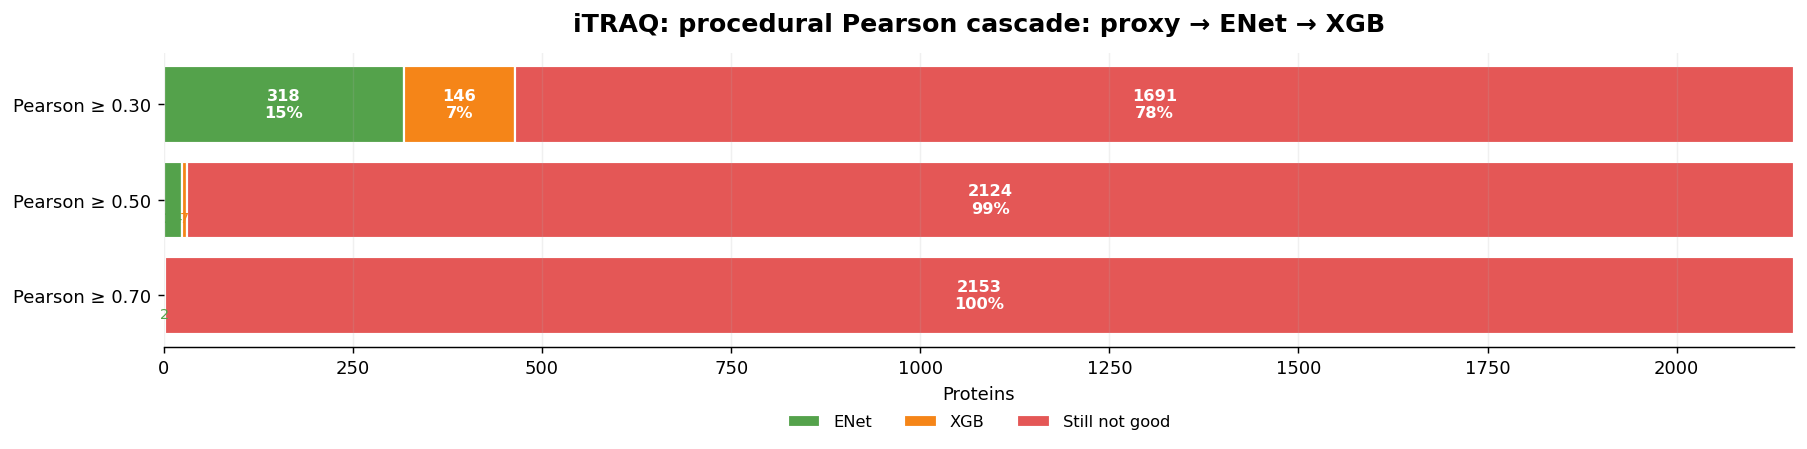


DATASET: TMT
Procedural Pearson cascade summary


C:\Users\hp\AppData\Local\Temp\ipykernel_16408\2297947463.py:31: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")


stage,Proxy Pearson,Proxy Spearman,Proxy baseline,ENet,XGB,Still not good
threshold,,,,,,
0.3,0,0,0,1508,277,370
0.5,0,0,0,92,162,1901
0.7,0,0,0,2,0,2153


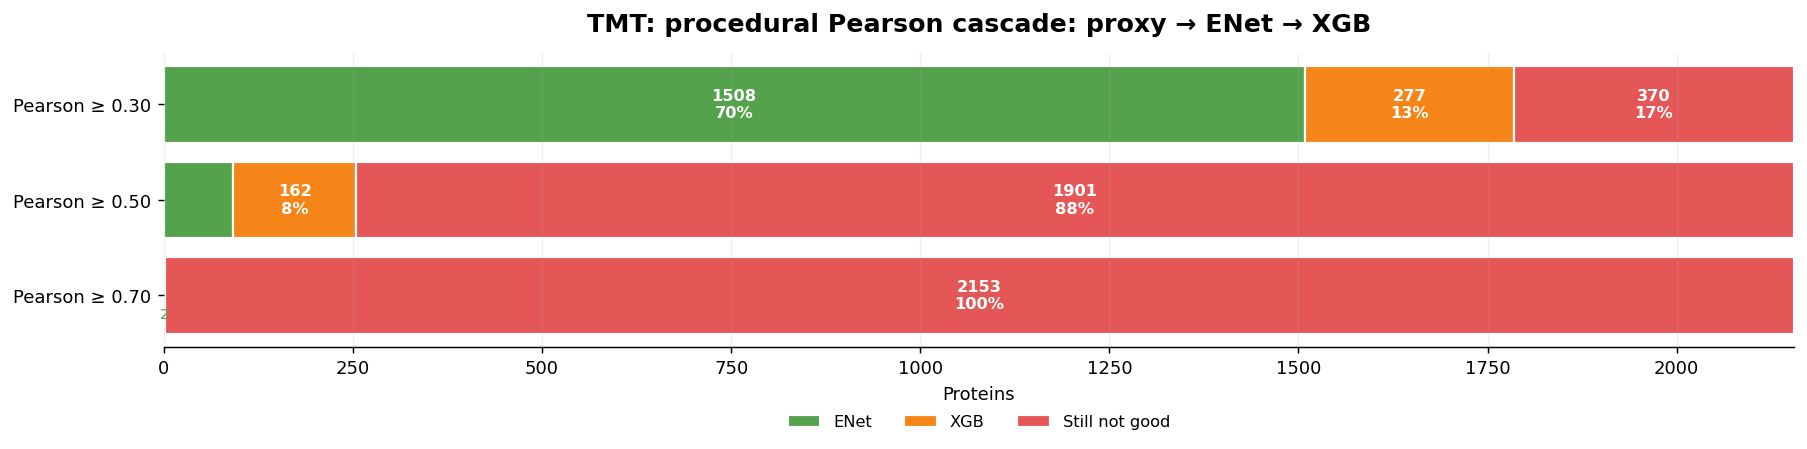


DATASET: LabelFree
Procedural Pearson cascade summary


C:\Users\hp\AppData\Local\Temp\ipykernel_16408\2297947463.py:31: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")


stage,Proxy Pearson,Proxy Spearman,Proxy baseline,ENet,XGB,Still not good
threshold,,,,,,
0.3,0,0,0,1326,248,581
0.5,0,0,0,779,168,1208
0.7,0,0,0,215,63,1877


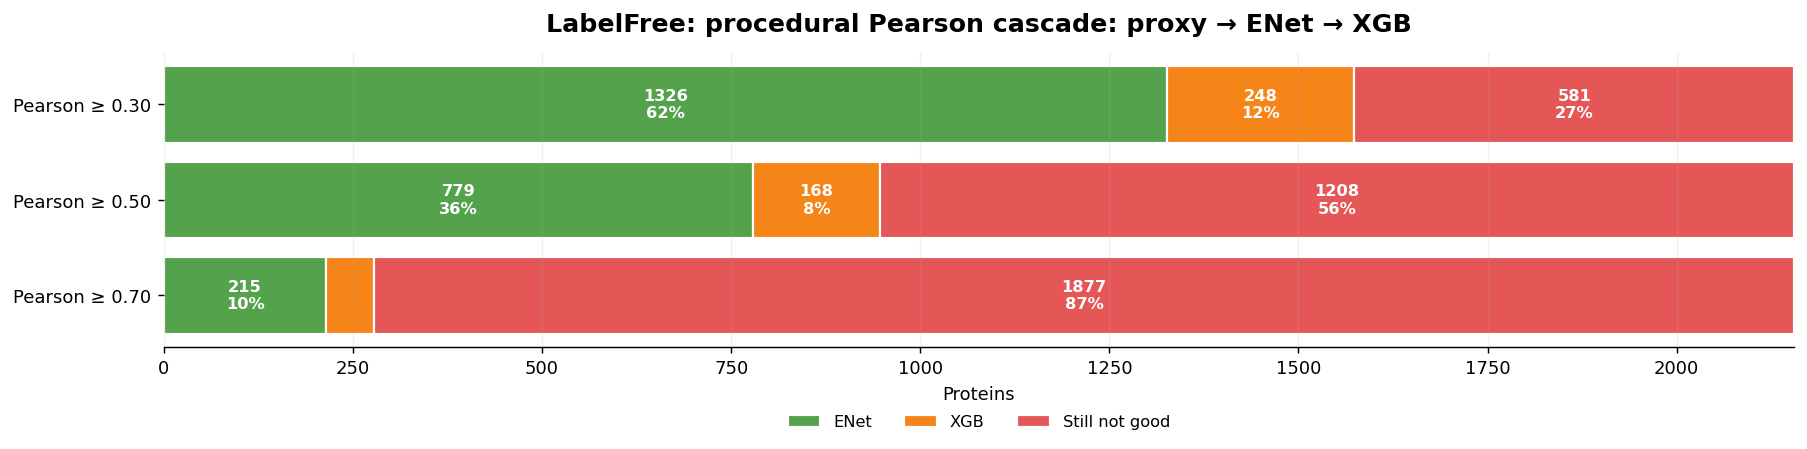

In [9]:
main_pearson_assignments_by_dataset = []
main_pearson_summaries = []

for key, tables in family_tables.items():
    dataset_name = tables["dataset_display"]
    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print("=" * 110)

    assignments = pd.concat(
        [
            procedural_metric_cascade(
                tables,
                thr,
                metric="test_pearson_corr",
                higher=True,
                include_sc=False,
            )
            for thr in PEARSON_GOOD_THRESHOLDS
        ],
        ignore_index=True,
    )

    summary = summarize_assignments(assignments, order=CASCADE_ORDER_BASE)
    main_pearson_assignments_by_dataset.append(assignments)
    main_pearson_summaries.append(summary)

    print("Procedural Pearson cascade summary")
    display(
        summary
        .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
        .reindex(columns=CASCADE_ORDER_BASE)
    )

    plot_stacked_partition_rows(
        summary,
        title=f"{dataset_name}: procedural Pearson cascade: proxy → ENet → XGB",
        order=CASCADE_ORDER_BASE,
        save_name=f"{key}_pearson_cascade_030_050_070.png",
        row_label_func=lambda thr: f"Pearson ≥ {thr:.2f}",
    )

main_pearson_assignments = pd.concat(main_pearson_assignments_by_dataset, ignore_index=True) if main_pearson_assignments_by_dataset else pd.DataFrame()
main_pearson_summary = pd.concat(main_pearson_summaries, ignore_index=True) if main_pearson_summaries else pd.DataFrame()

if SAVE_OUTPUTS:
    main_pearson_assignments.to_csv(EXPORT_TABLE_DIR / "main_pearson_assignments.csv", index=False)
    main_pearson_summary.to_csv(EXPORT_TABLE_DIR / "main_pearson_summary.csv", index=False)


## 7. Pearson threshold sweep

This is the same procedural cascade, but for many Pearson thresholds.


DATASET: iTRAQ


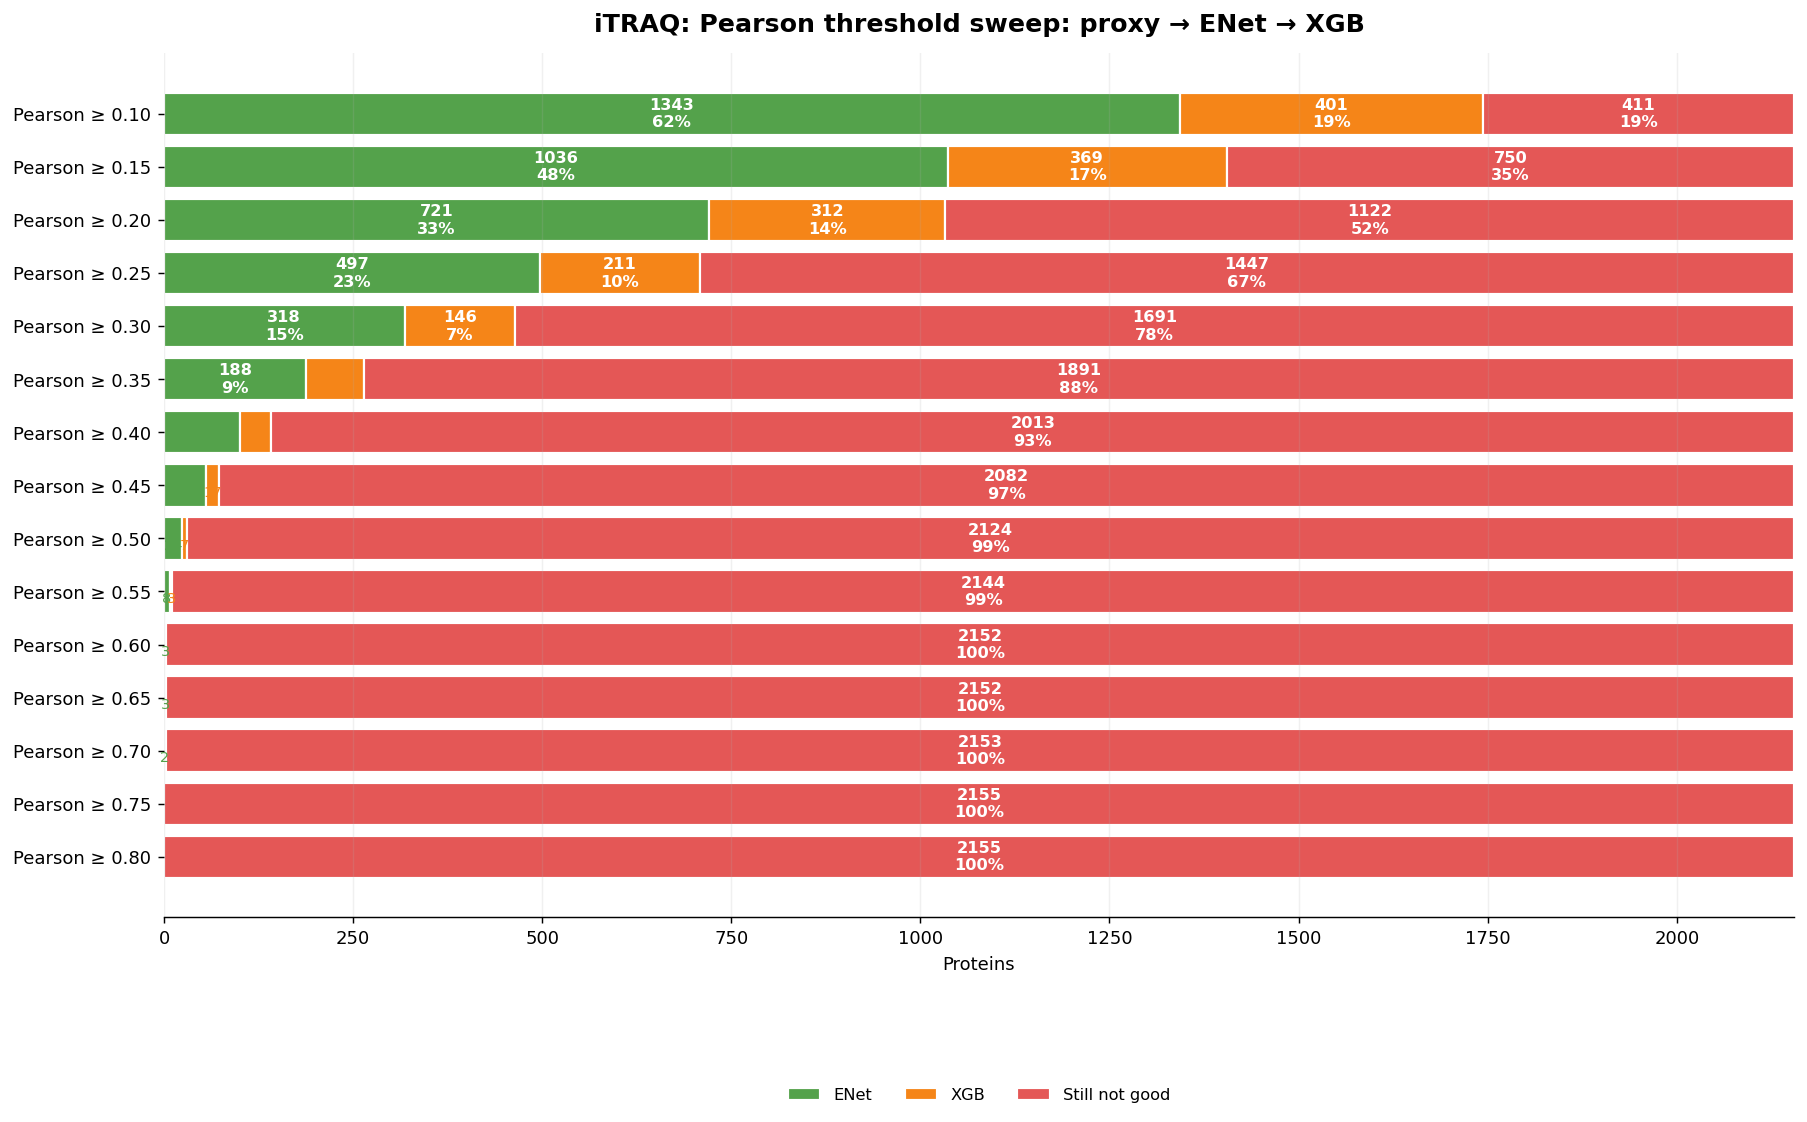


DATASET: TMT


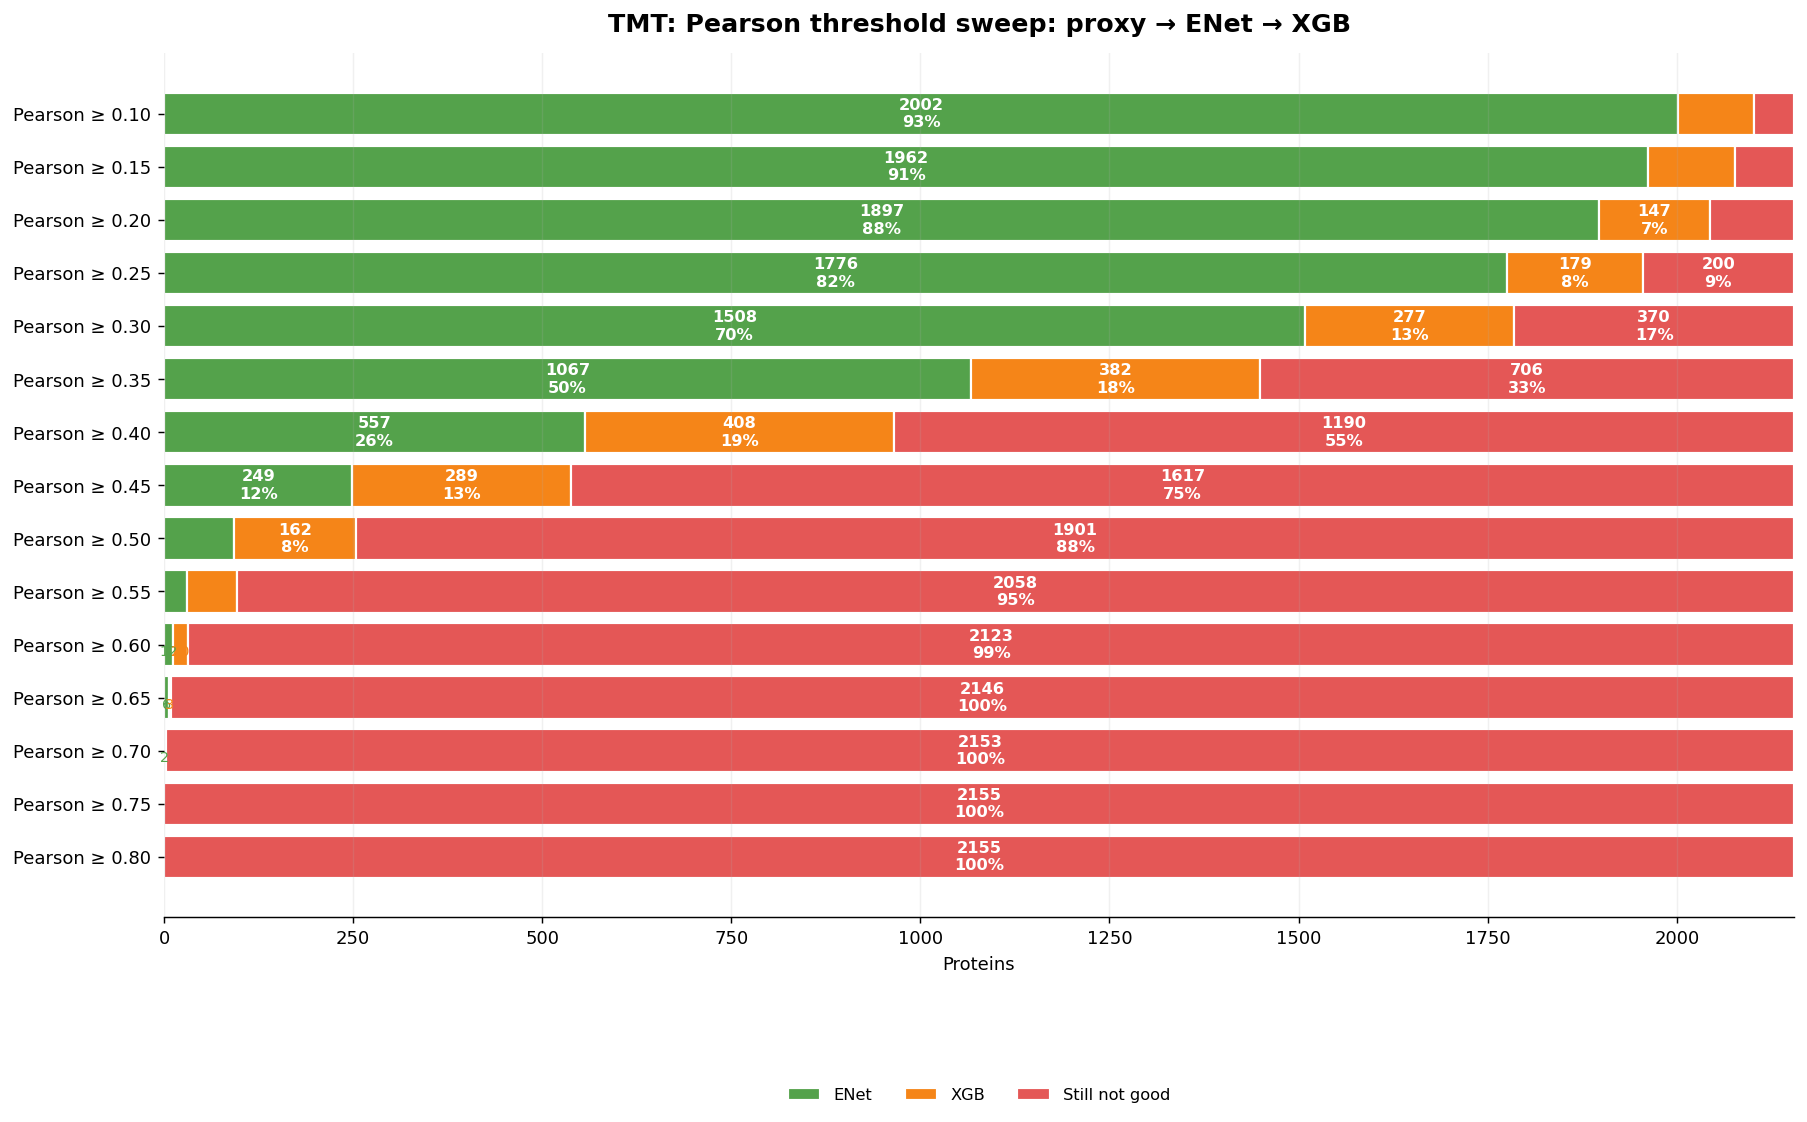


DATASET: LabelFree


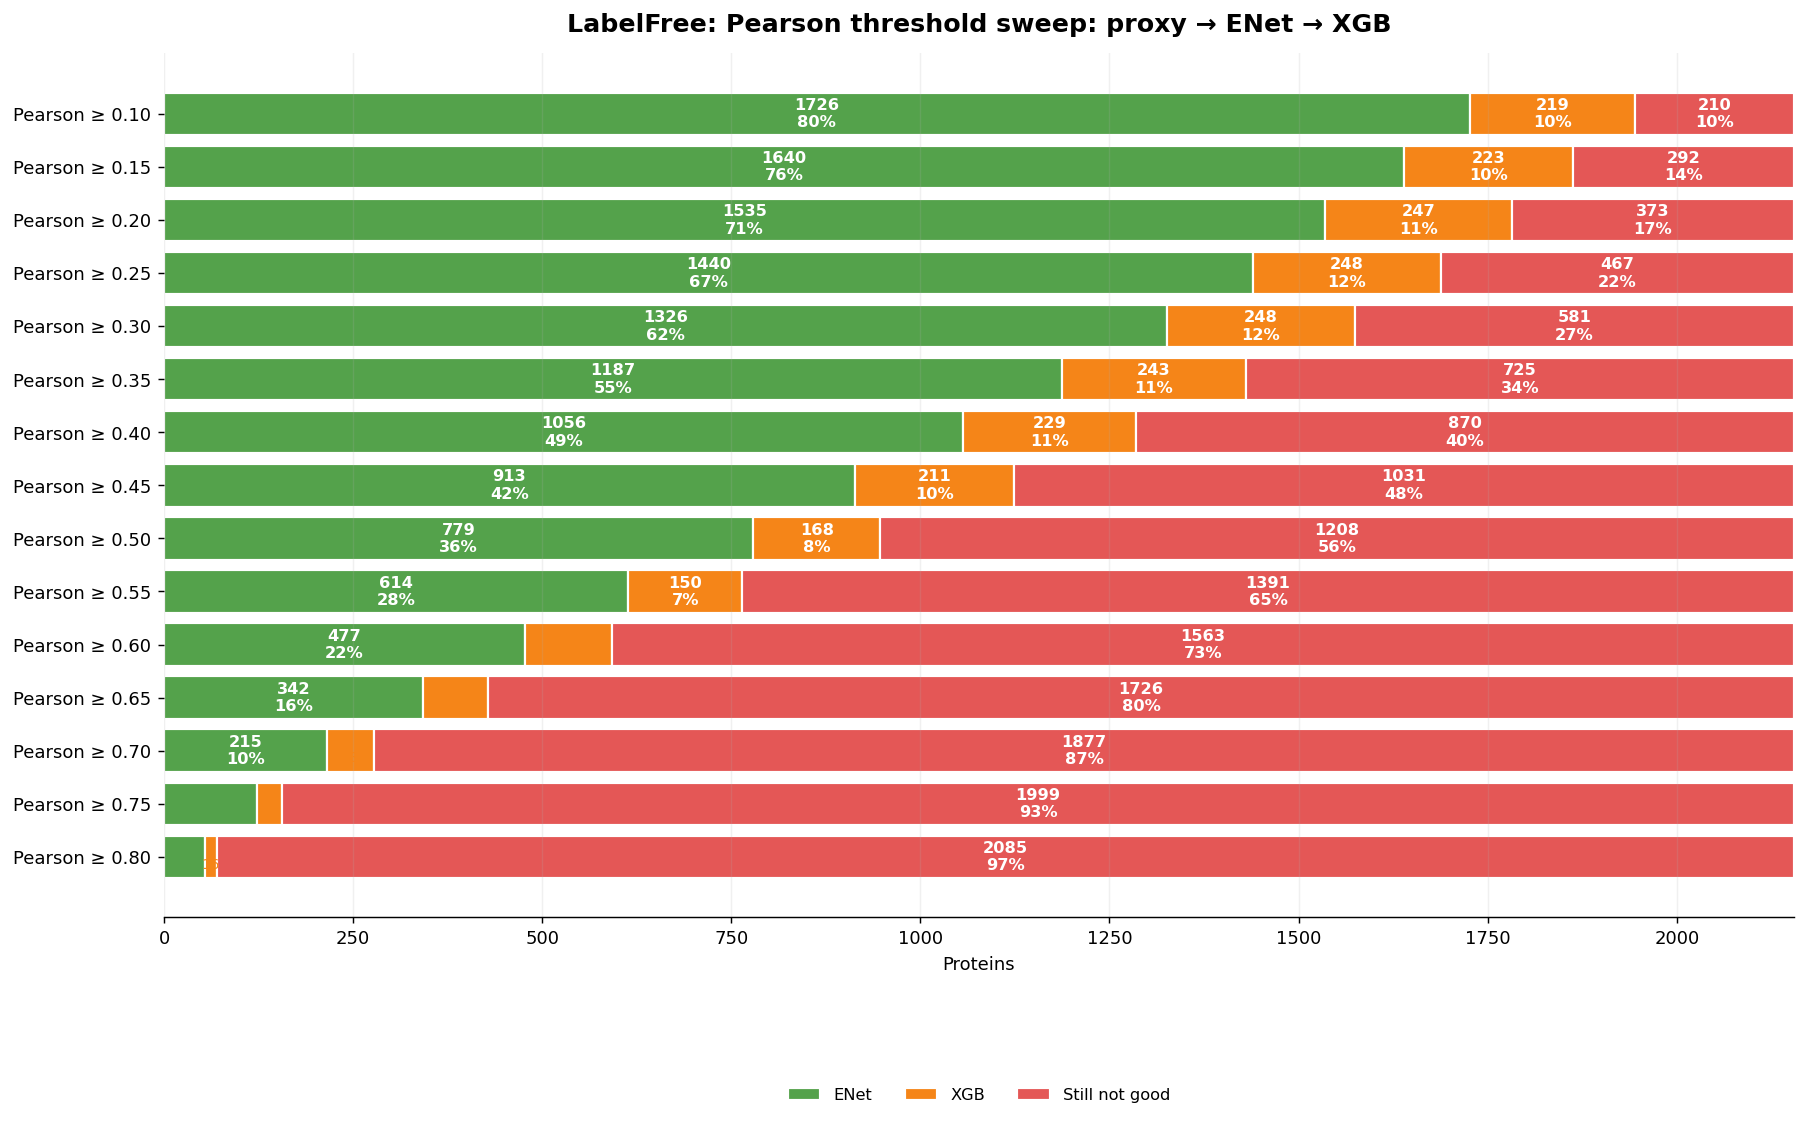

In [10]:
pearson_sweep_assignments_by_dataset = []
pearson_sweep_summaries = []

for key, tables in family_tables.items():
    dataset_name = tables["dataset_display"]
    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print("=" * 110)

    assignments = pd.concat(
        [
            procedural_metric_cascade(
                tables,
                thr,
                metric="test_pearson_corr",
                higher=True,
                include_sc=False,
            )
            for thr in PEARSON_SWEEP_THRESHOLDS
        ],
        ignore_index=True,
    )

    summary = summarize_assignments(assignments, order=CASCADE_ORDER_BASE)
    pearson_sweep_assignments_by_dataset.append(assignments)
    pearson_sweep_summaries.append(summary)

    plot_stacked_partition_rows(
        summary,
        title=f"{dataset_name}: Pearson threshold sweep: proxy → ENet → XGB",
        order=CASCADE_ORDER_BASE,
        save_name=f"{key}_pearson_threshold_sweep.png",
        figsize=(14, max(5, 0.45 * len(PEARSON_SWEEP_THRESHOLDS) + 2.0)),
        row_label_func=lambda thr: f"Pearson ≥ {thr:.2f}",
    )

pearson_sweep_assignments = pd.concat(pearson_sweep_assignments_by_dataset, ignore_index=True) if pearson_sweep_assignments_by_dataset else pd.DataFrame()
pearson_sweep_summary = pd.concat(pearson_sweep_summaries, ignore_index=True) if pearson_sweep_summaries else pd.DataFrame()

if SAVE_OUTPUTS:
    pearson_sweep_assignments.to_csv(EXPORT_TABLE_DIR / "pearson_threshold_sweep_assignments.csv", index=False)
    pearson_sweep_summary.to_csv(EXPORT_TABLE_DIR / "pearson_threshold_sweep_summary.csv", index=False)


## 8. Proxy-correlation threshold inspection

This optional section mirrors the CCLE notebook's proxy-correlation inspection.

It asks a different question from the procedural cascade:

> If a same-gene/proxy baseline is only considered eligible when its stored proxy correlation is at least a threshold, how many proteins are eligible and also good on the validation set?

The section runs only if the validation metrics contain a recognizable proxy-correlation metadata column, for example `proxy_corr`, `same_gene_corr`, `same_gene_pearson`, `full_same_gene_corr`, or similar.

In [11]:
from src.utils_val import find_proxy_corr_column, proxy_corr_threshold_assignments_for_dataset

PROXY_CORR_THRESHOLDS = [round(x, 2) for x in np.arange(0.00, 0.95, 0.05)]
USE_ABS_PROXY_CORR_FOR_ELIGIBILITY = True

COLOR_MAP.update({
    "Eligible and good": "#4C78A8",
    "Eligible but not good": "#F58518",
    "No eligible proxy": "#E45756",
})

PROXY_ELIGIBILITY_ORDER = [
    "Eligible and good",
    "Eligible but not good",
    "No eligible proxy",
]

PROXY_CORR_CANDIDATES = [
    "proxy_corr",
    "same_gene_corr",
    "same_gene_correlation",
    "same_gene_pearson",
    "same_gene_spearman",
    "full_same_gene_corr",
    "full_same_gene_pearson",
    "full_same_gene_spearman",
    "train_same_gene_corr",
    "train_proxy_corr",
    "proxy_pearson_corr",
    "proxy_spearman_corr",
    "corr",
    "correlation",
]






uv.configure_runtime_globals(
    PROXY_CORR_THRESHOLDS=PROXY_CORR_THRESHOLDS,
    USE_ABS_PROXY_CORR_FOR_ELIGIBILITY=USE_ABS_PROXY_CORR_FOR_ELIGIBILITY,
    PROXY_ELIGIBILITY_ORDER=PROXY_ELIGIBILITY_ORDER,
    PROXY_CORR_CANDIDATES=PROXY_CORR_CANDIDATES,
    PROXY_STAGES=PROXY_STAGES,
    COLOR_MAP=COLOR_MAP,
    SAVE_OUTPUTS=SAVE_OUTPUTS,
    FIGURE_DIR=FIGURE_DIR,
)

proxy_corr_all_assignments = []
proxy_corr_all_summaries = []

for key, tables in family_tables.items():
    dataset_name = tables["dataset_display"]
    assignments, corr_col = proxy_corr_threshold_assignments_for_dataset(tables, metrics_partition)

    if assignments.empty:
        continue

    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print(f"Proxy correlation column: {corr_col}")
    print("=" * 110)

    for pred_thr in PEARSON_GOOD_THRESHOLDS:
        sub_assignments = assignments[assignments["prediction_threshold"].eq(pred_thr)].copy()
        summary = summarize_assignments(sub_assignments, order=PROXY_ELIGIBILITY_ORDER)
        proxy_corr_all_summaries.append(summary.assign(prediction_threshold=pred_thr))

        plot_stacked_partition_rows(
            summary,
            title=(
                f"{dataset_name}: proxy-correlation eligibility sweep "
                f"with validation Pearson ≥ {pred_thr:.2f}"
            ),
            order=PROXY_ELIGIBILITY_ORDER,
            save_name=f"{key}_proxy_corr_threshold_pred_{str(pred_thr).replace('.', '_')}.png",
            figsize=(14, max(5, 0.45 * len(PROXY_CORR_THRESHOLDS) + 2.0)),
            row_label_func=lambda thr: f"Proxy corr ≥ {thr:.2f}",
        )

    proxy_corr_all_assignments.append(assignments)

proxy_corr_assignments = pd.concat(proxy_corr_all_assignments, ignore_index=True) if proxy_corr_all_assignments else pd.DataFrame()
proxy_corr_summary = pd.concat(proxy_corr_all_summaries, ignore_index=True) if proxy_corr_all_summaries else pd.DataFrame()

if SAVE_OUTPUTS and len(proxy_corr_assignments):
    proxy_corr_assignments.to_csv(EXPORT_TABLE_DIR / "proxy_corr_threshold_assignments.csv", index=False)
    proxy_corr_summary.to_csv(EXPORT_TABLE_DIR / "proxy_corr_threshold_summary.csv", index=False)

No proxy/baseline rows for iTRAQ.
No proxy/baseline rows for TMT.
No proxy/baseline rows for LabelFree.


## 9. MSE threshold sweep

Lower MSE is better, so a protein is successful when:

```text
test_mse <= threshold
```

Because MSE scale can differ across validation datasets, this section includes both absolute MSE thresholds and percentile-based thresholds.


DATASET: iTRAQ


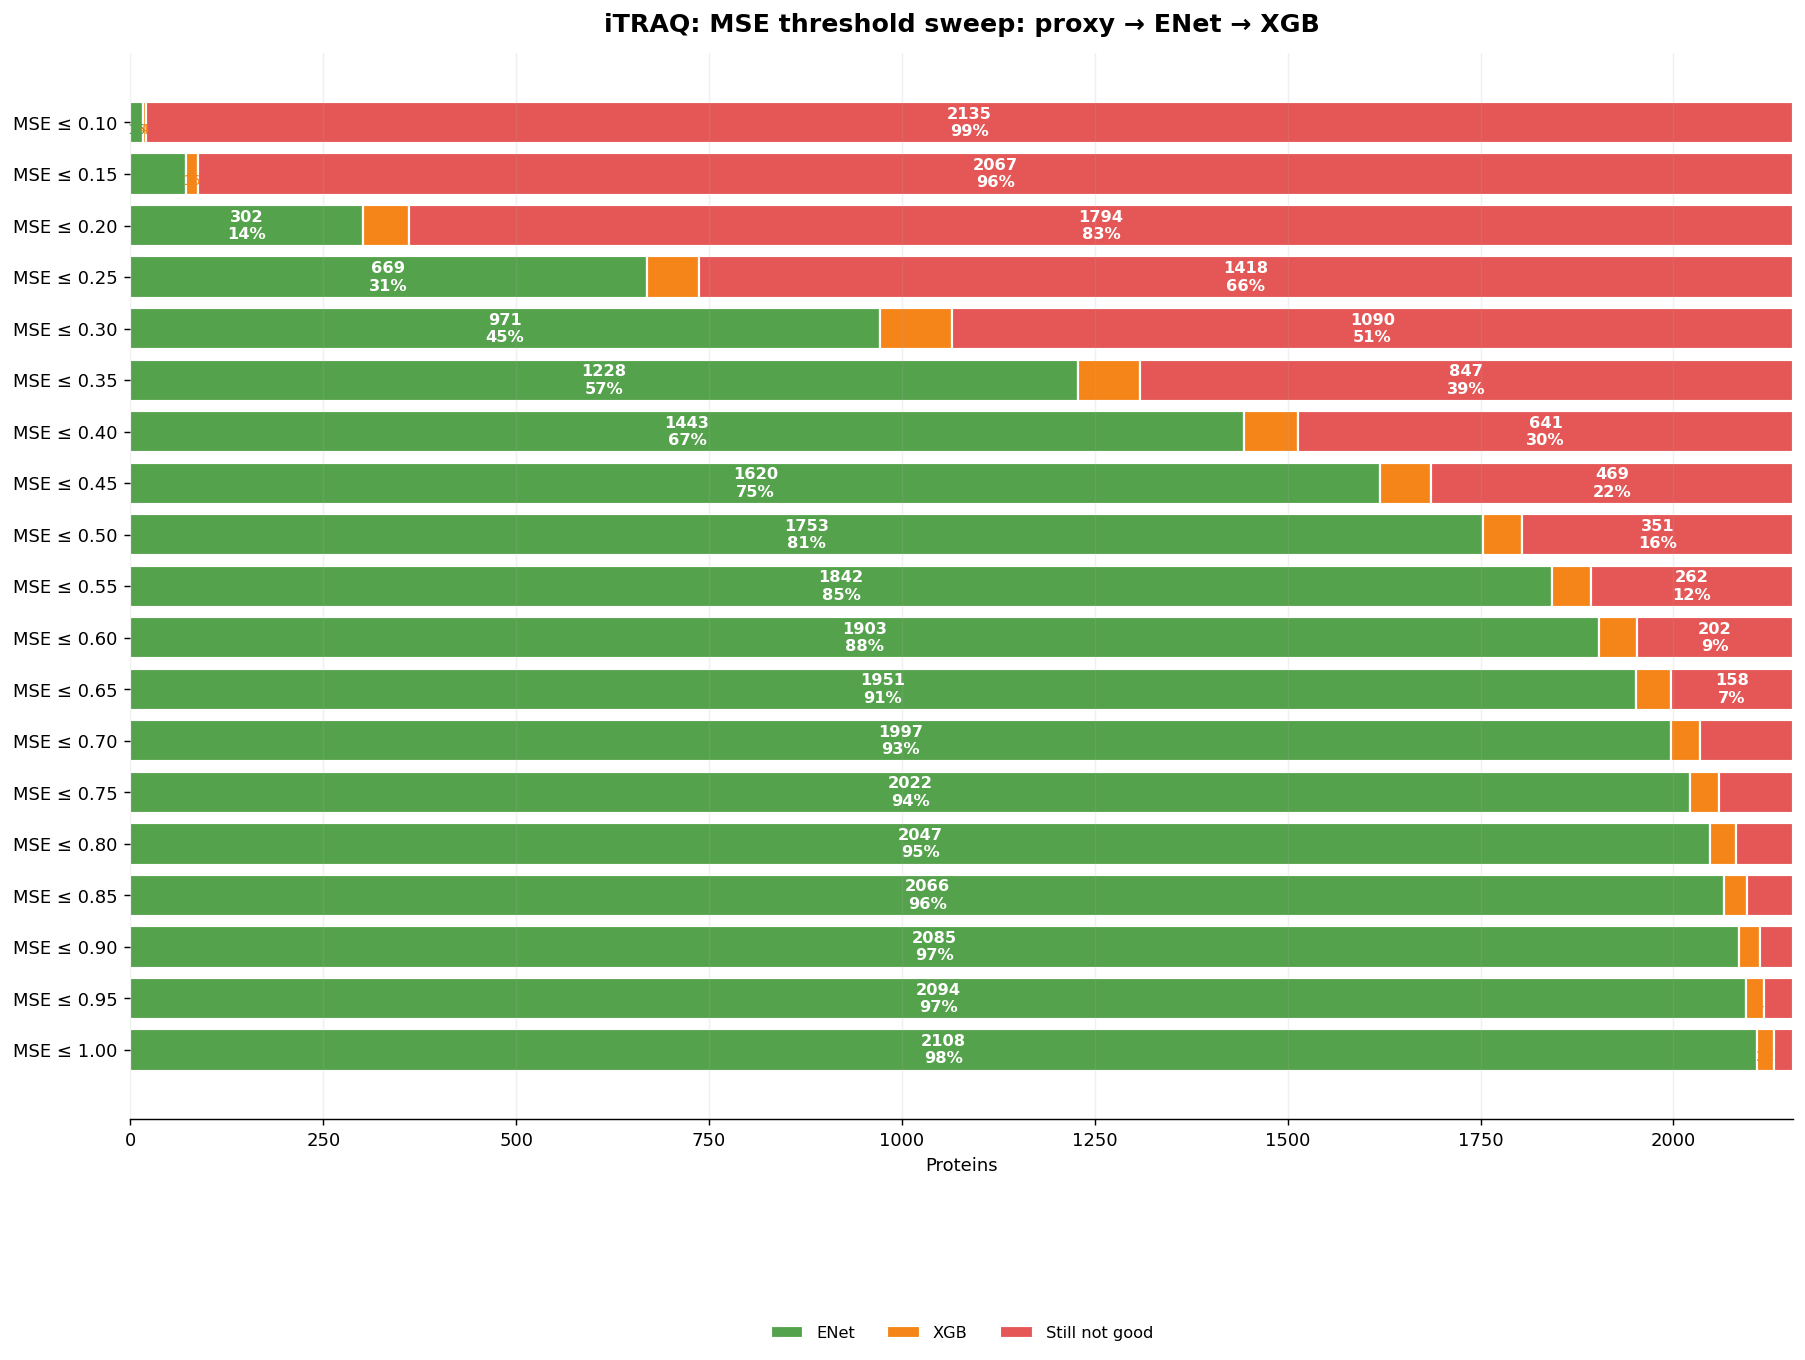


DATASET: TMT


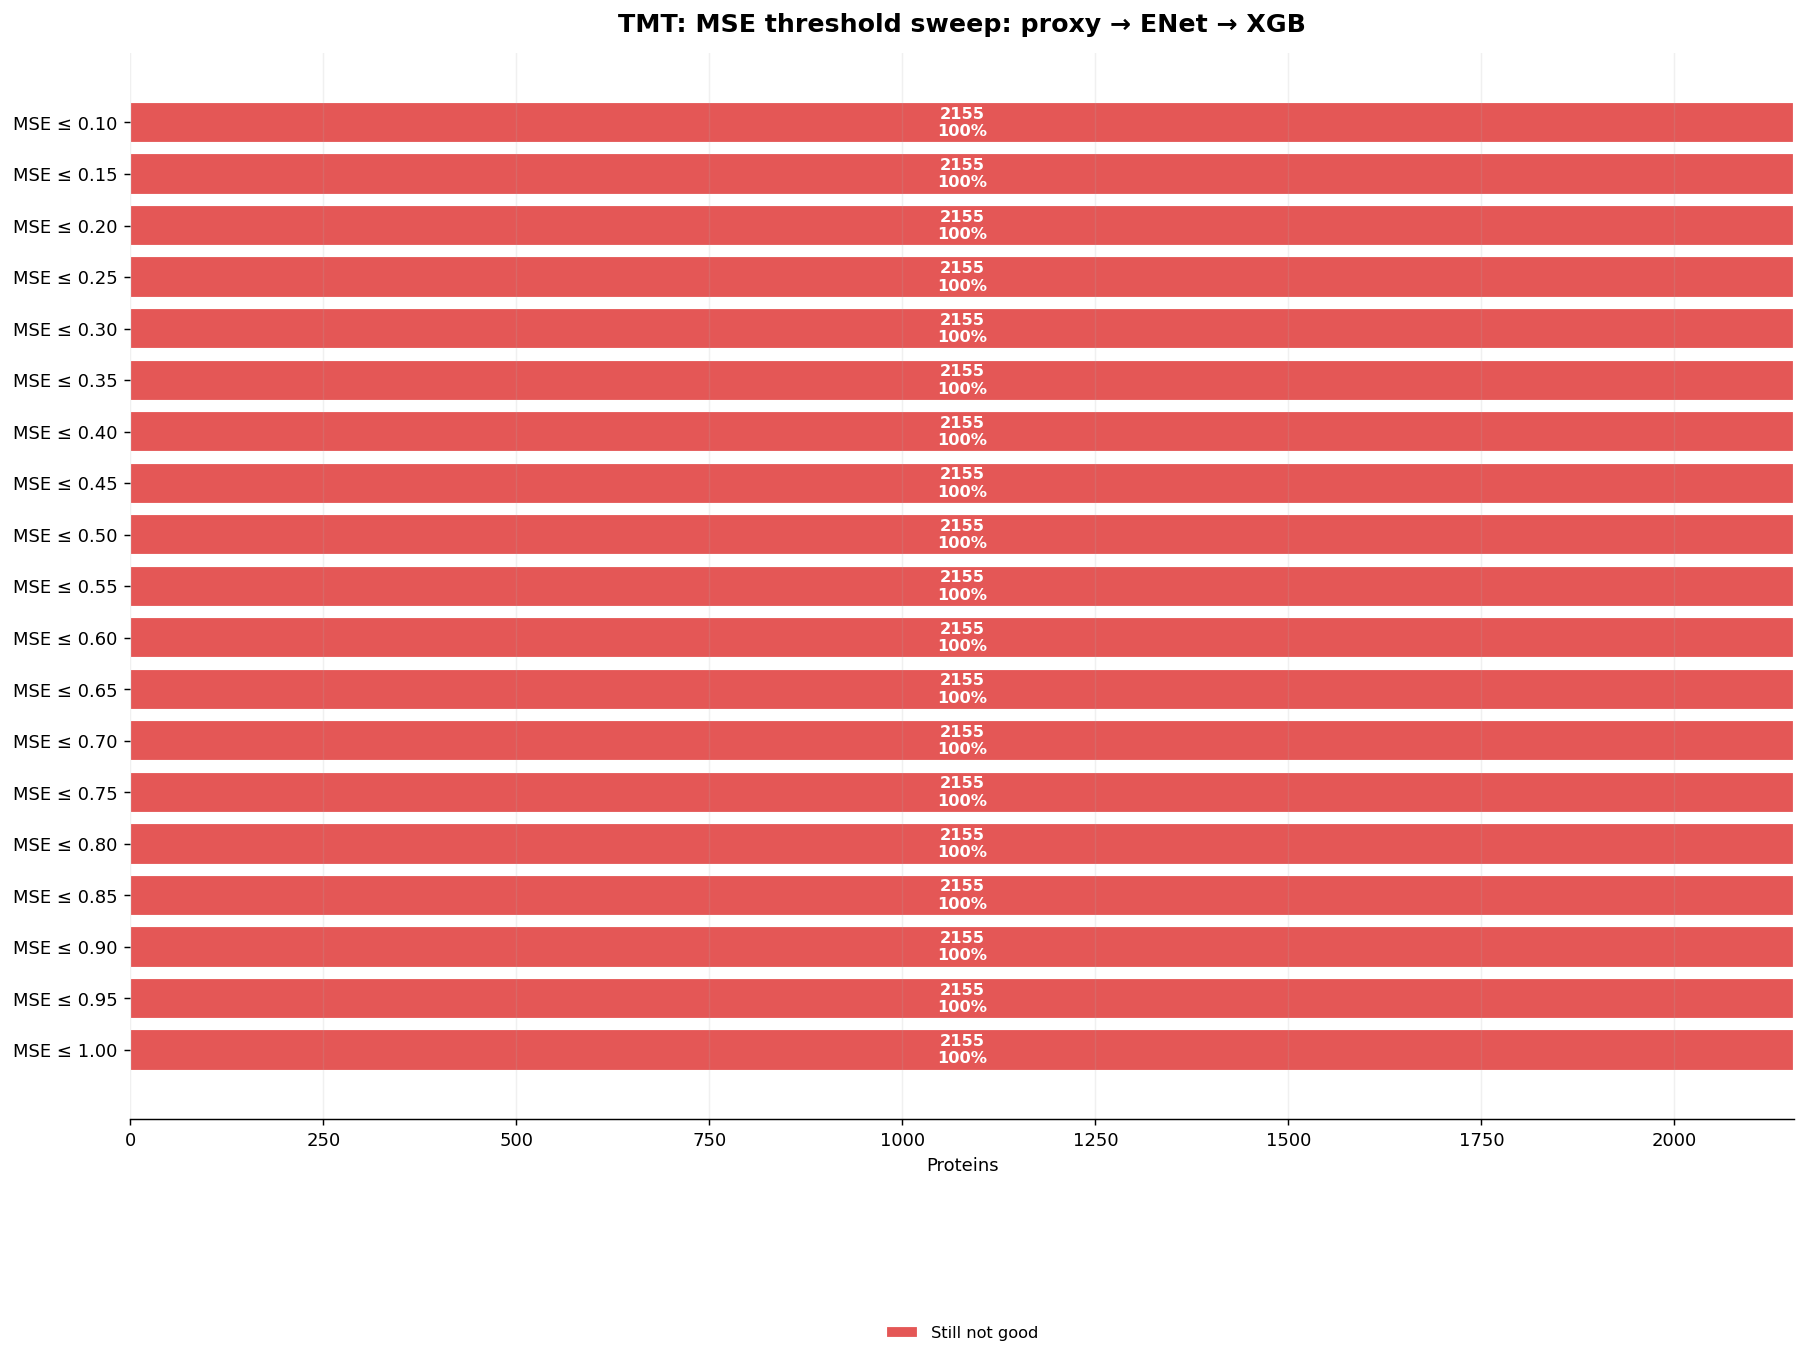


DATASET: LabelFree


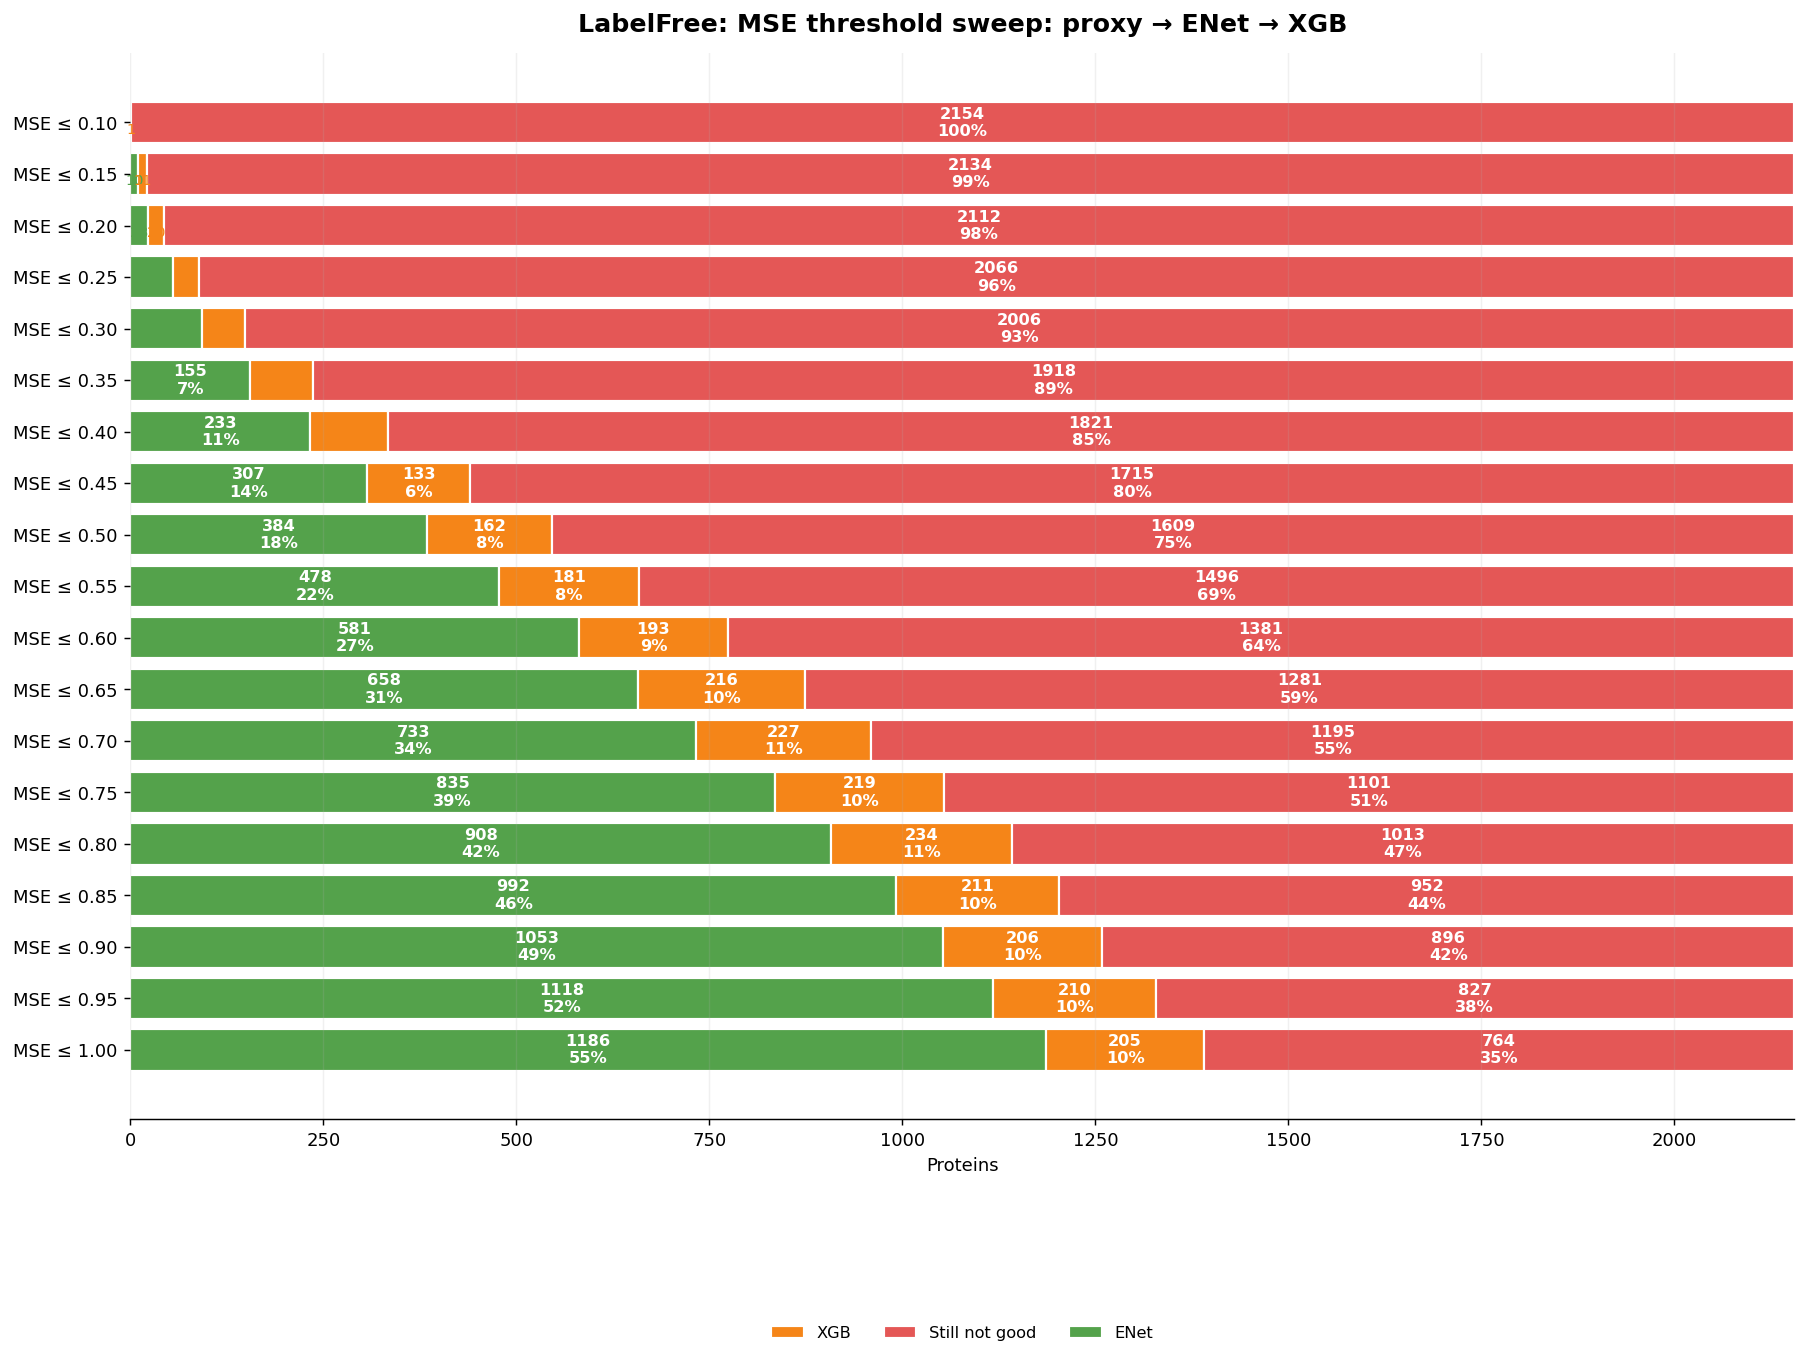

In [12]:
mse_sweep_assignments_by_dataset = []
mse_sweep_summaries = []

for key, tables in family_tables.items():
    dataset_name = tables["dataset_display"]
    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print("=" * 110)

    assignments = pd.concat(
        [
            procedural_metric_cascade(
                tables,
                thr,
                metric="test_mse",
                higher=False,
                include_sc=False,
            )
            for thr in MSE_SWEEP_THRESHOLDS
        ],
        ignore_index=True,
    )

    summary = summarize_assignments(assignments, order=CASCADE_ORDER_BASE)
    mse_sweep_assignments_by_dataset.append(assignments)
    mse_sweep_summaries.append(summary)

    plot_stacked_partition_rows(
        summary,
        title=f"{dataset_name}: MSE threshold sweep: proxy → ENet → XGB",
        order=CASCADE_ORDER_BASE,
        save_name=f"{key}_mse_threshold_sweep.png",
        figsize=(14, max(5, 0.45 * len(MSE_SWEEP_THRESHOLDS) + 2.0)),
        row_label_func=lambda thr: f"MSE ≤ {thr:.2f}",
    )

mse_sweep_assignments = pd.concat(mse_sweep_assignments_by_dataset, ignore_index=True) if mse_sweep_assignments_by_dataset else pd.DataFrame()
mse_sweep_summary = pd.concat(mse_sweep_summaries, ignore_index=True) if mse_sweep_summaries else pd.DataFrame()

if SAVE_OUTPUTS:
    mse_sweep_assignments.to_csv(EXPORT_TABLE_DIR / "mse_threshold_sweep_assignments.csv", index=False)
    mse_sweep_summary.to_csv(EXPORT_TABLE_DIR / "mse_threshold_sweep_summary.csv", index=False)



DATASET: iTRAQ
Dataset-specific MSE thresholds: {'p10': '0.195', 'p25': '0.25', 'p50': '0.35', 'p75': '0.497'}


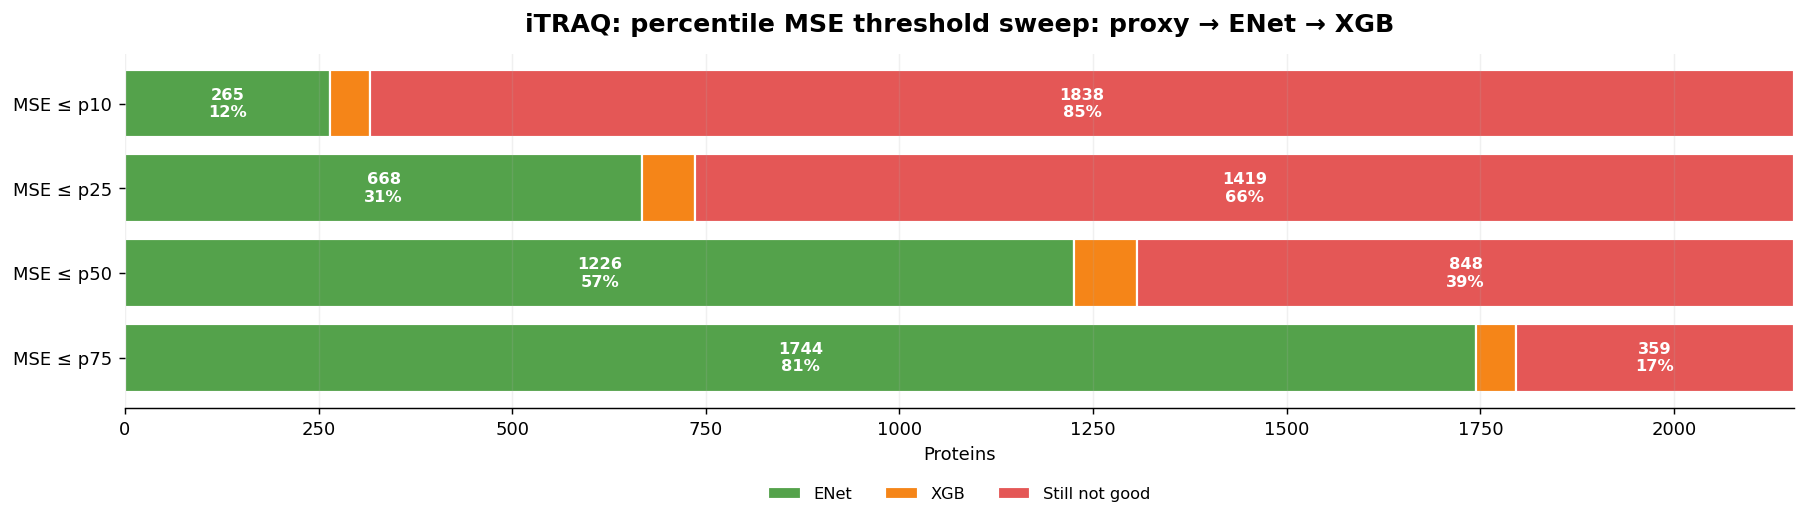


DATASET: TMT
Dataset-specific MSE thresholds: {'p10': '4.57', 'p25': '6.82', 'p50': '10', 'p75': '14.3'}


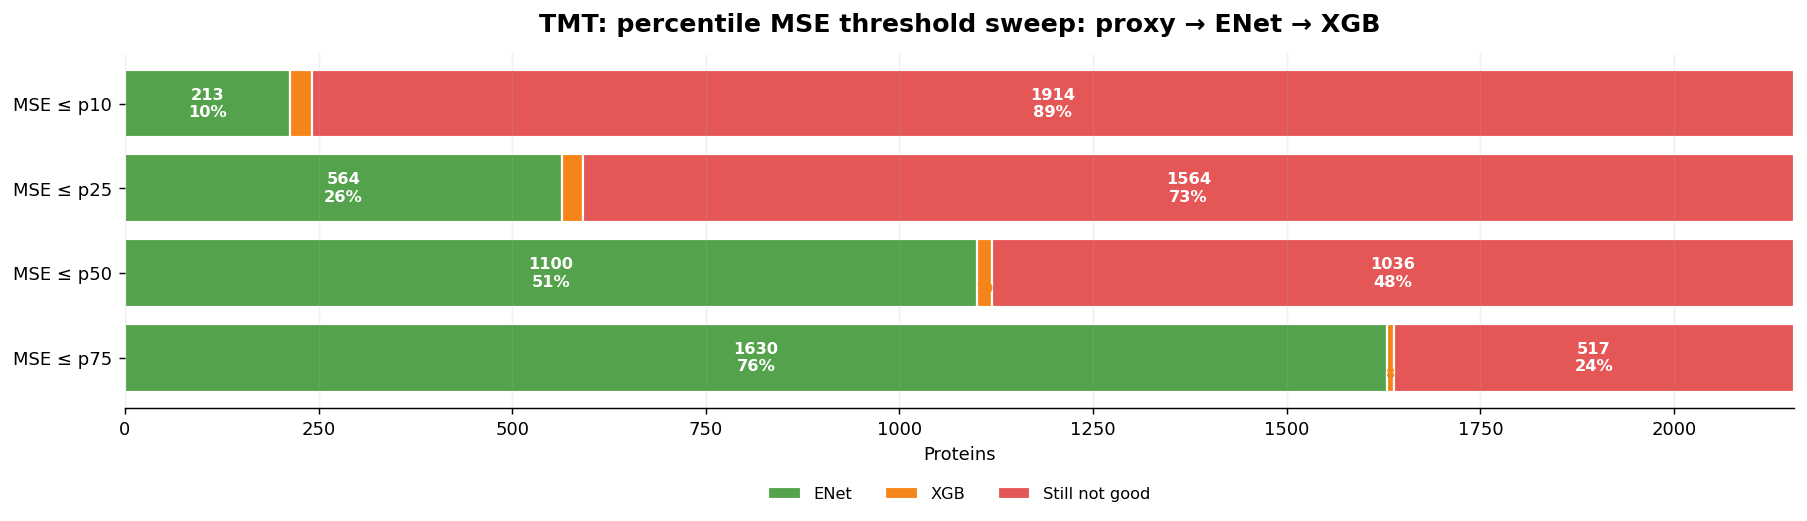


DATASET: LabelFree
Dataset-specific MSE thresholds: {'p10': '0.398', 'p25': '0.581', 'p50': '0.911', 'p75': '1.41'}


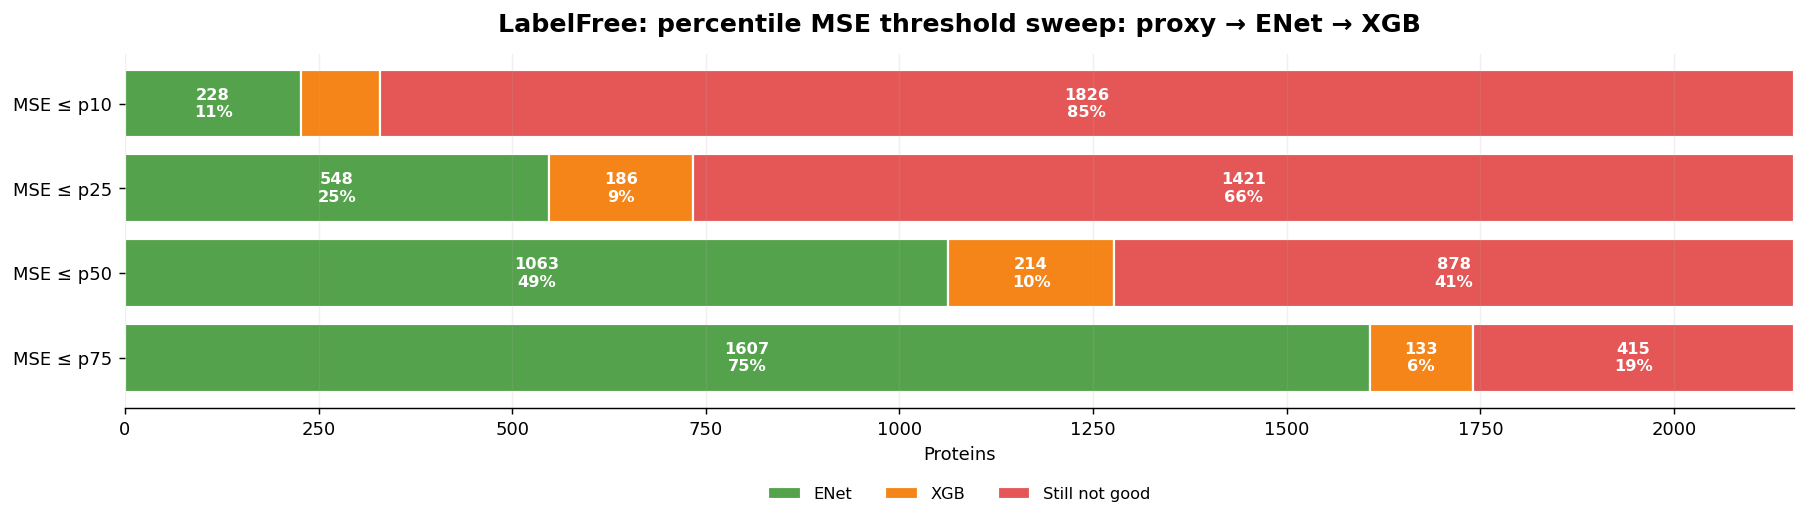

In [13]:
mse_percentile_assignments_by_dataset = []
mse_percentile_summaries = []

for key, tables in family_tables.items():
    dataset_name = tables["dataset_display"]

    # Use the best available MSE across base families to define dataset-specific MSE thresholds.
    candidate_mse = []
    for name in ["proxy_best_mse", "enet_best_mse", "xgb_best_mse"]:
        df = tables[name]
        if len(df) and "test_mse" in df.columns:
            candidate_mse.append(df[["protein", "test_mse"]].copy())

    if not candidate_mse:
        print(f"No MSE values for {dataset_name}")
        continue

    all_mse = pd.concat(candidate_mse, ignore_index=True).dropna(subset=["test_mse"])
    if all_mse.empty:
        print(f"No finite MSE values for {dataset_name}")
        continue

    thresholds = [float(all_mse["test_mse"].quantile(p / 100.0)) for p in MSE_PERCENTILE_THRESHOLDS]
    pct_to_thr = dict(zip(MSE_PERCENTILE_THRESHOLDS, thresholds))

    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print("Dataset-specific MSE thresholds:", {f"p{p}": fmt_num(t) for p, t in pct_to_thr.items()})
    print("=" * 110)

    assignments = pd.concat(
        [
            procedural_metric_cascade(
                tables,
                pct_to_thr[p],
                metric="test_mse",
                higher=False,
                include_sc=False,
            ).assign(mse_percentile_threshold=p)
            for p in MSE_PERCENTILE_THRESHOLDS
        ],
        ignore_index=True,
    )

    # For plotting, replace threshold values with the percentile labels so the y axis is clean.
    plot_assignments = assignments.copy()
    plot_assignments["threshold"] = plot_assignments["mse_percentile_threshold"].astype(float)

    summary = summarize_assignments(plot_assignments, order=CASCADE_ORDER_BASE)
    mse_percentile_assignments_by_dataset.append(assignments)
    mse_percentile_summaries.append(summary)

    plot_stacked_partition_rows(
        summary,
        title=f"{dataset_name}: percentile MSE threshold sweep: proxy → ENet → XGB",
        order=CASCADE_ORDER_BASE,
        save_name=f"{key}_mse_percentile_threshold_sweep.png",
        figsize=(14, max(4, 0.55 * len(MSE_PERCENTILE_THRESHOLDS) + 2.0)),
        row_label_func=lambda p: f"MSE ≤ p{int(p)}",
    )

mse_percentile_assignments = pd.concat(mse_percentile_assignments_by_dataset, ignore_index=True) if mse_percentile_assignments_by_dataset else pd.DataFrame()
mse_percentile_summary = pd.concat(mse_percentile_summaries, ignore_index=True) if mse_percentile_summaries else pd.DataFrame()

if SAVE_OUTPUTS:
    mse_percentile_assignments.to_csv(EXPORT_TABLE_DIR / "mse_percentile_threshold_assignments.csv", index=False)
    mse_percentile_summary.to_csv(EXPORT_TABLE_DIR / "mse_percentile_threshold_summary.csv", index=False)


## 10. MSE without a fixed threshold

This mirrors the CCLE notebook's no-threshold MSE inspection:

1. **MSE winner partition**: which family has the lowest MSE per protein?
2. **Procedural MSE improvement partition**: starting from proxy, does ENet lower MSE, and then does XGB lower it further?

In [14]:
from src.utils_val import mse_procedural_improvement_assignments, mse_winner_assignments


DATASET: iTRAQ


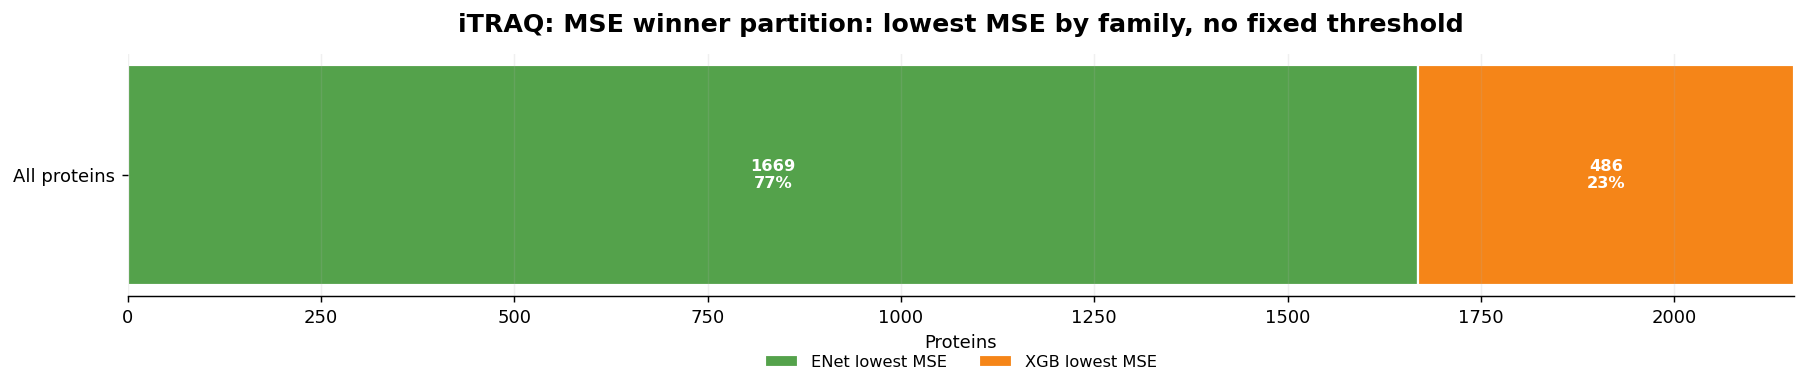

,dataset,stage,proteins,percent
0,iTRAQ,ENet lowest MSE,1669,77.447796
1,iTRAQ,XGB lowest MSE,486,22.552204


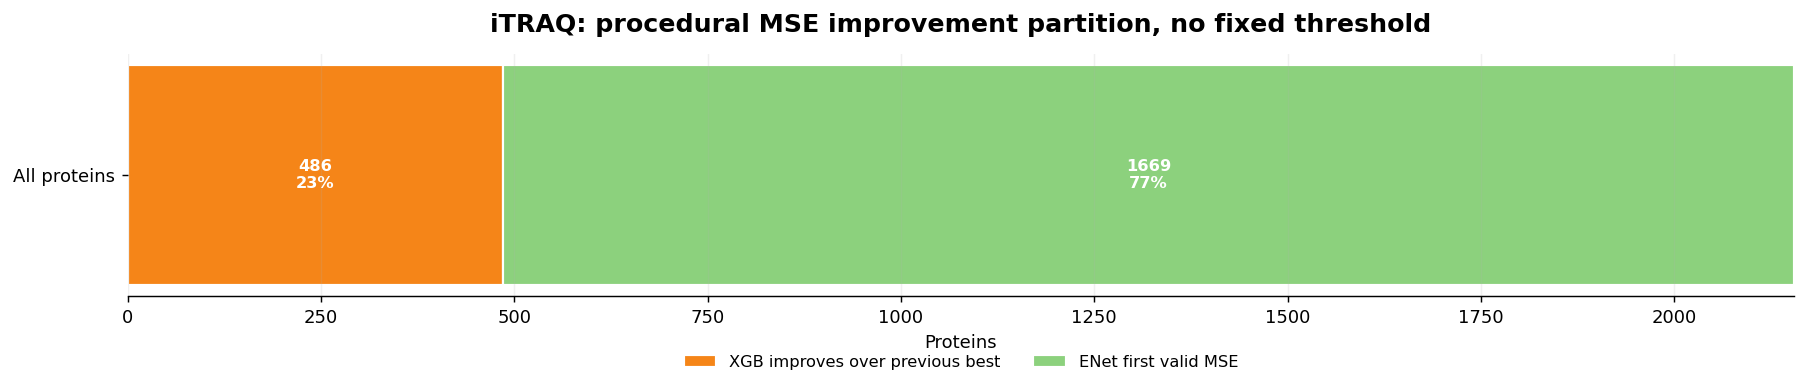

,dataset,stage,proteins,percent
0,iTRAQ,XGB improves over previous best,486,22.552204
1,iTRAQ,ENet first valid MSE,1669,77.447796



DATASET: TMT


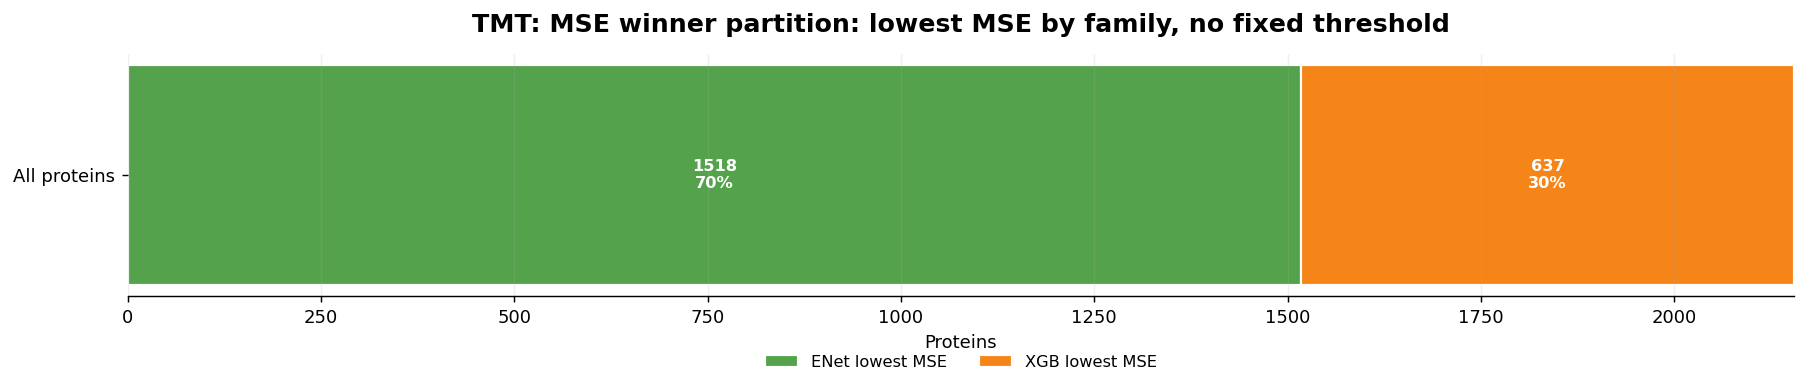

,dataset,stage,proteins,percent
0,TMT,ENet lowest MSE,1518,70.440835
1,TMT,XGB lowest MSE,637,29.559165


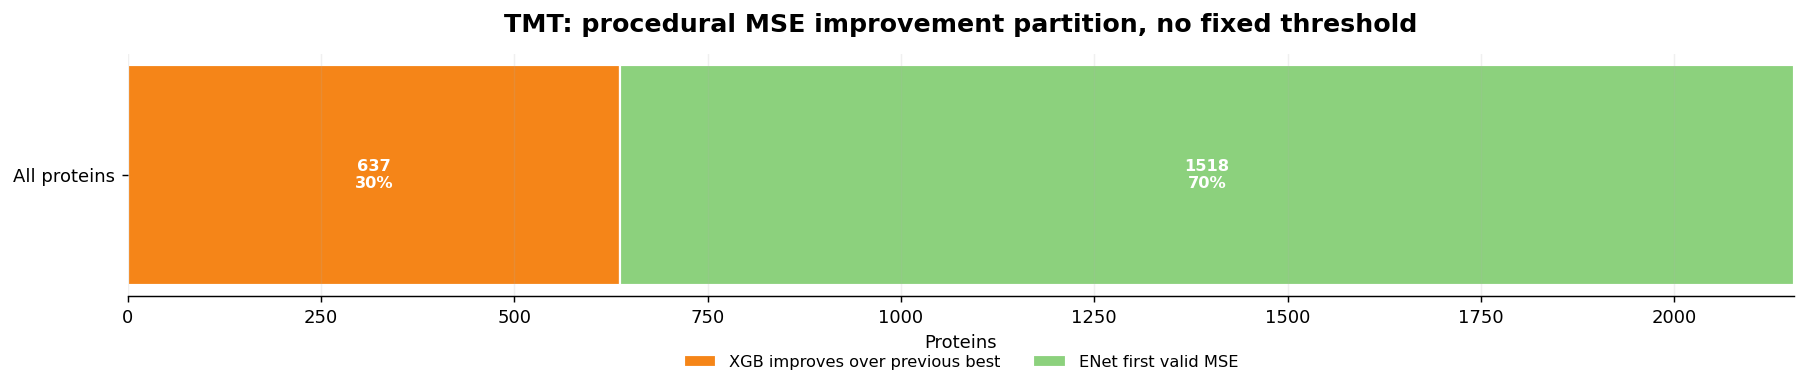

,dataset,stage,proteins,percent
0,TMT,XGB improves over previous best,637,29.559165
1,TMT,ENet first valid MSE,1518,70.440835



DATASET: LabelFree


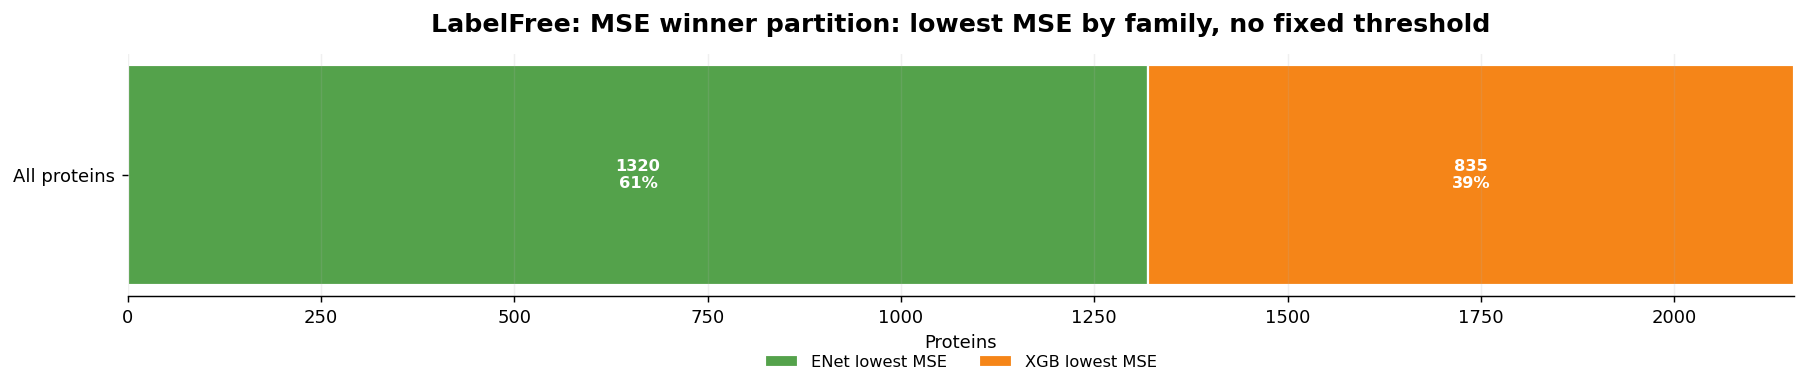

,dataset,stage,proteins,percent
0,LabelFree,ENet lowest MSE,1320,61.2529
1,LabelFree,XGB lowest MSE,835,38.7471


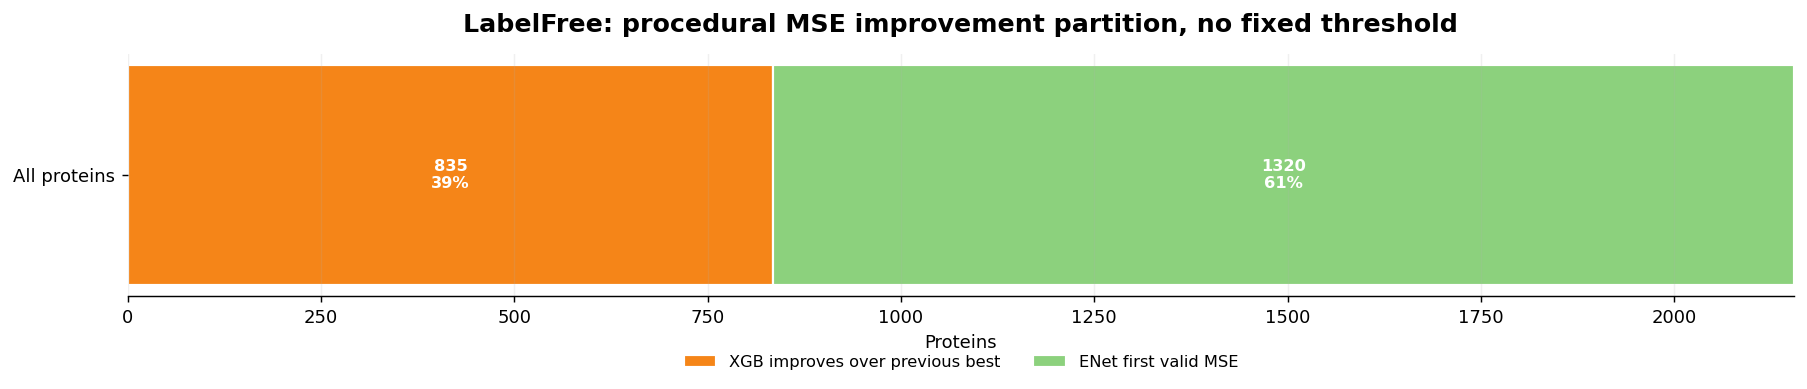

,dataset,stage,proteins,percent
0,LabelFree,XGB improves over previous best,835,38.7471
1,LabelFree,ENet first valid MSE,1320,61.2529


In [15]:
mse_winner_all = []
mse_improvement_all = []
mse_winner_summaries = []
mse_improvement_summaries = []

for key, tables in family_tables.items():
    dataset_name = tables["dataset_display"]
    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print("=" * 110)

    winner = mse_winner_assignments(tables)
    improvement = mse_procedural_improvement_assignments(tables)

    mse_winner_all.append(winner)
    mse_improvement_all.append(improvement)

    winner_summary = plot_single_partition(
        winner,
        title=f"{dataset_name}: MSE winner partition: lowest MSE by family, no fixed threshold",
        order=MSE_WINNER_ORDER,
        save_name=f"{key}_mse_winner_partition.png",
    )
    mse_winner_summaries.append(winner_summary)

    improvement_summary = plot_single_partition(
        improvement,
        title=f"{dataset_name}: procedural MSE improvement partition, no fixed threshold",
        order=MSE_IMPROVEMENT_ORDER,
        save_name=f"{key}_mse_procedural_improvement_partition.png",
    )
    mse_improvement_summaries.append(improvement_summary)

mse_winner = pd.concat(mse_winner_all, ignore_index=True) if mse_winner_all else pd.DataFrame()
mse_improvement = pd.concat(mse_improvement_all, ignore_index=True) if mse_improvement_all else pd.DataFrame()
mse_winner_summary = pd.concat(mse_winner_summaries, ignore_index=True) if mse_winner_summaries else pd.DataFrame()
mse_improvement_summary = pd.concat(mse_improvement_summaries, ignore_index=True) if mse_improvement_summaries else pd.DataFrame()

if SAVE_OUTPUTS:
    mse_winner.to_csv(EXPORT_TABLE_DIR / "mse_winner_assignments.csv", index=False)
    mse_improvement.to_csv(EXPORT_TABLE_DIR / "mse_procedural_improvement_assignments.csv", index=False)
    mse_winner_summary.to_csv(EXPORT_TABLE_DIR / "mse_winner_summary.csv", index=False)
    mse_improvement_summary.to_csv(EXPORT_TABLE_DIR / "mse_procedural_improvement_summary.csv", index=False)


## 11. Optional cosine threshold analyses

Cosine similarity exists in the validation metrics from notebook 8. This section is not in the original procedural CCLE notebook, but is useful for matching the validation metrics view.


DATASET: iTRAQ


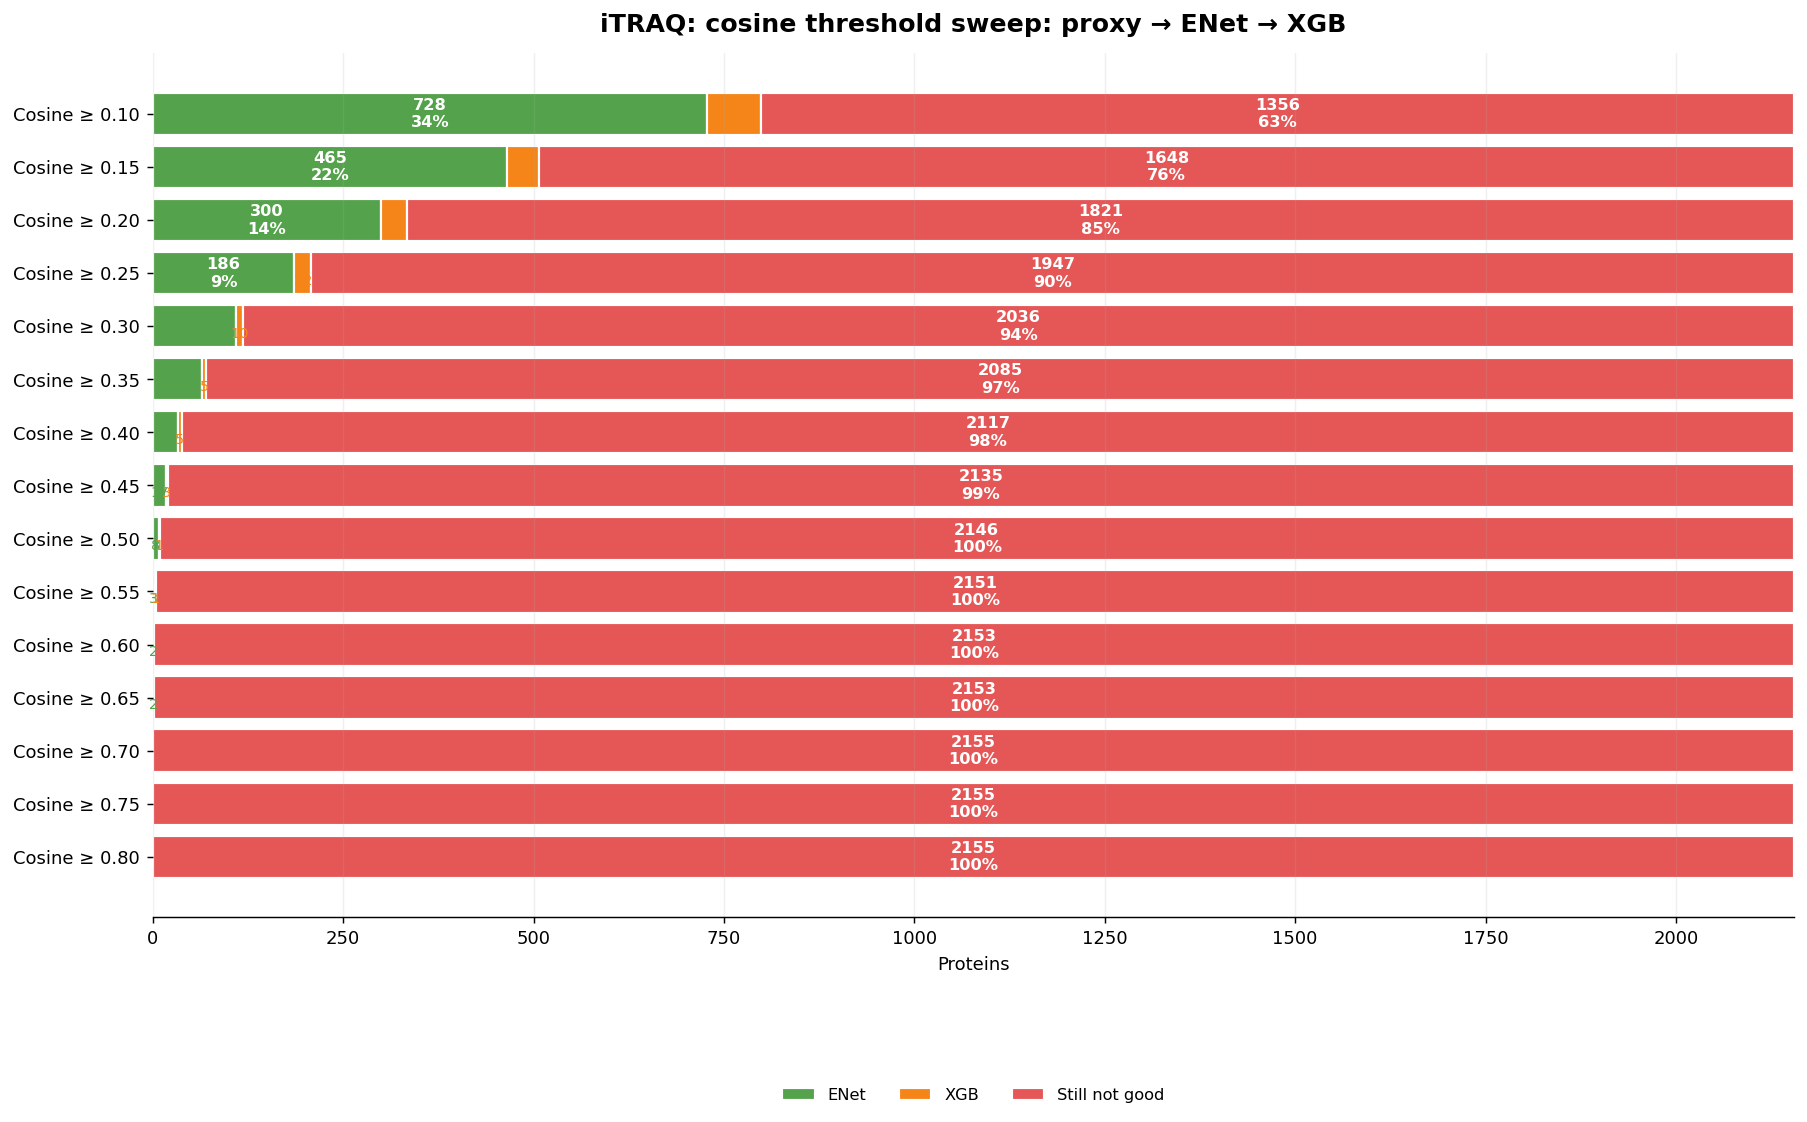


DATASET: TMT


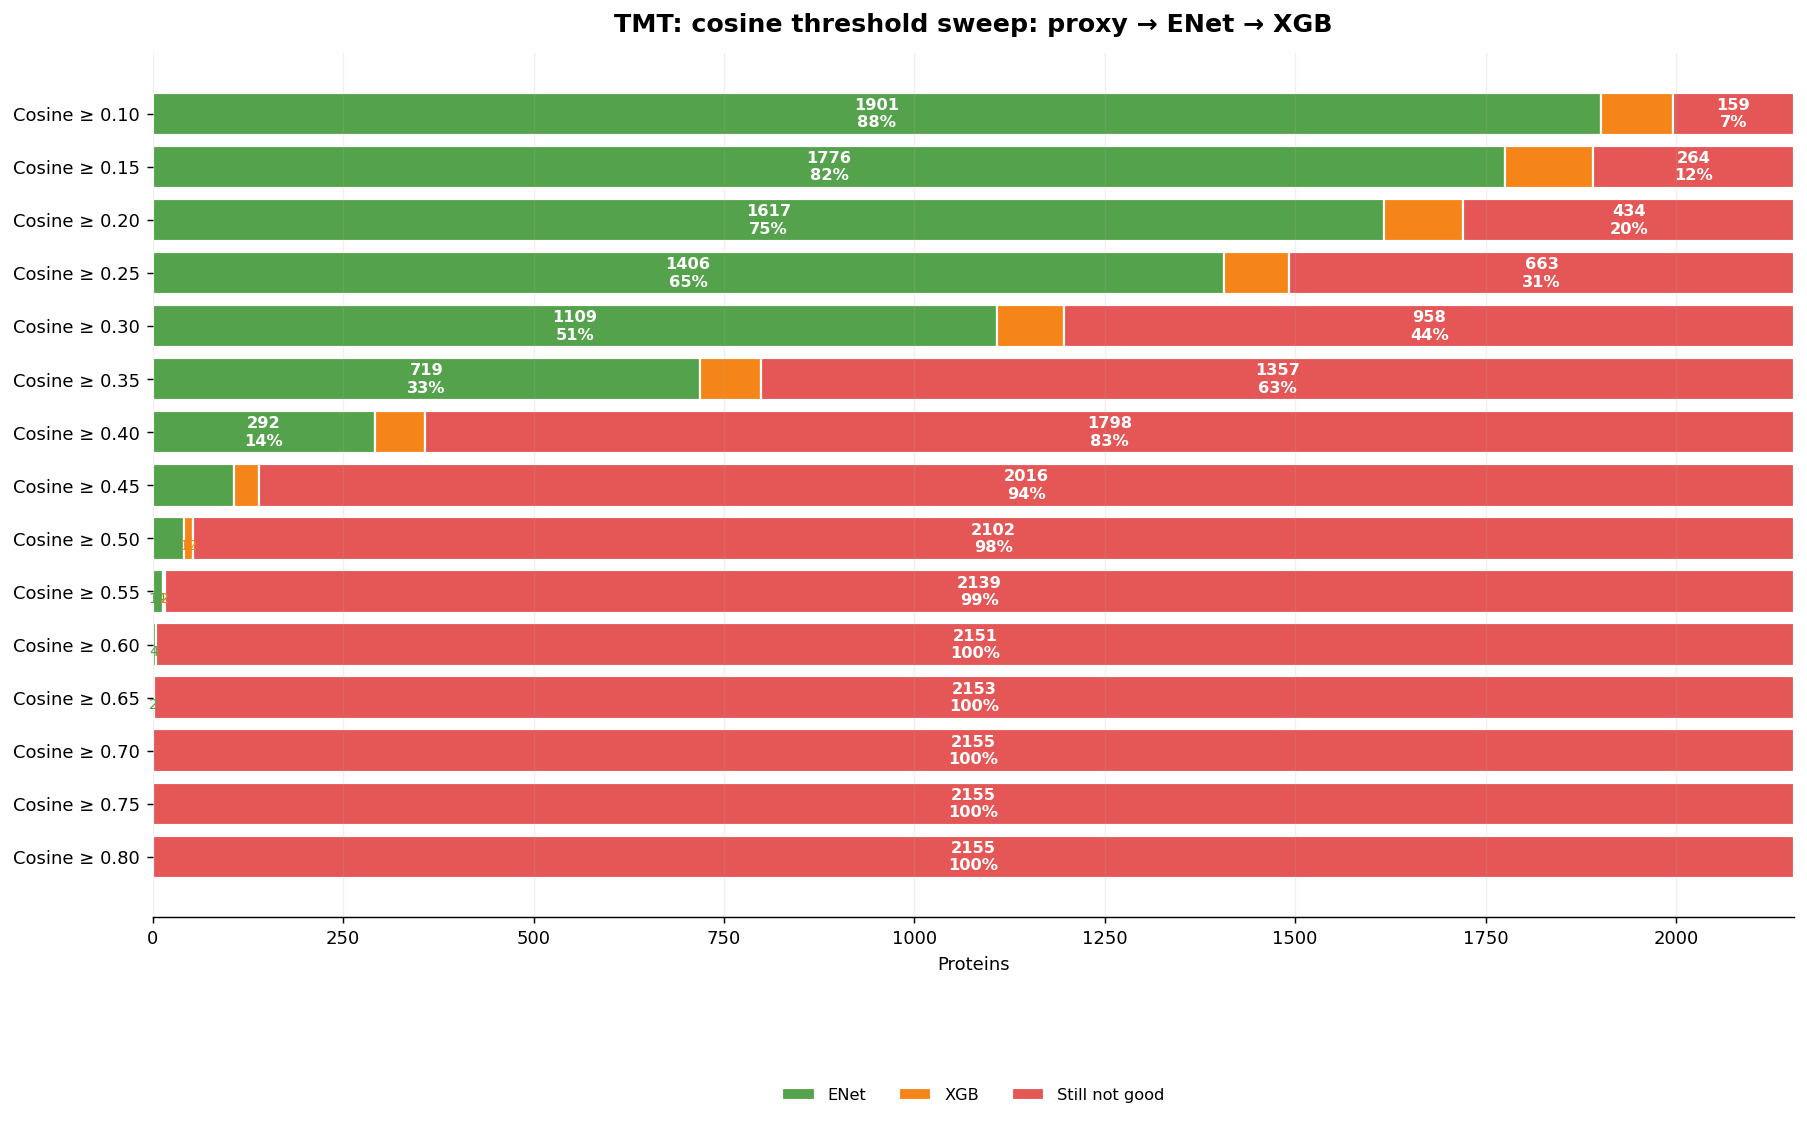


DATASET: LabelFree


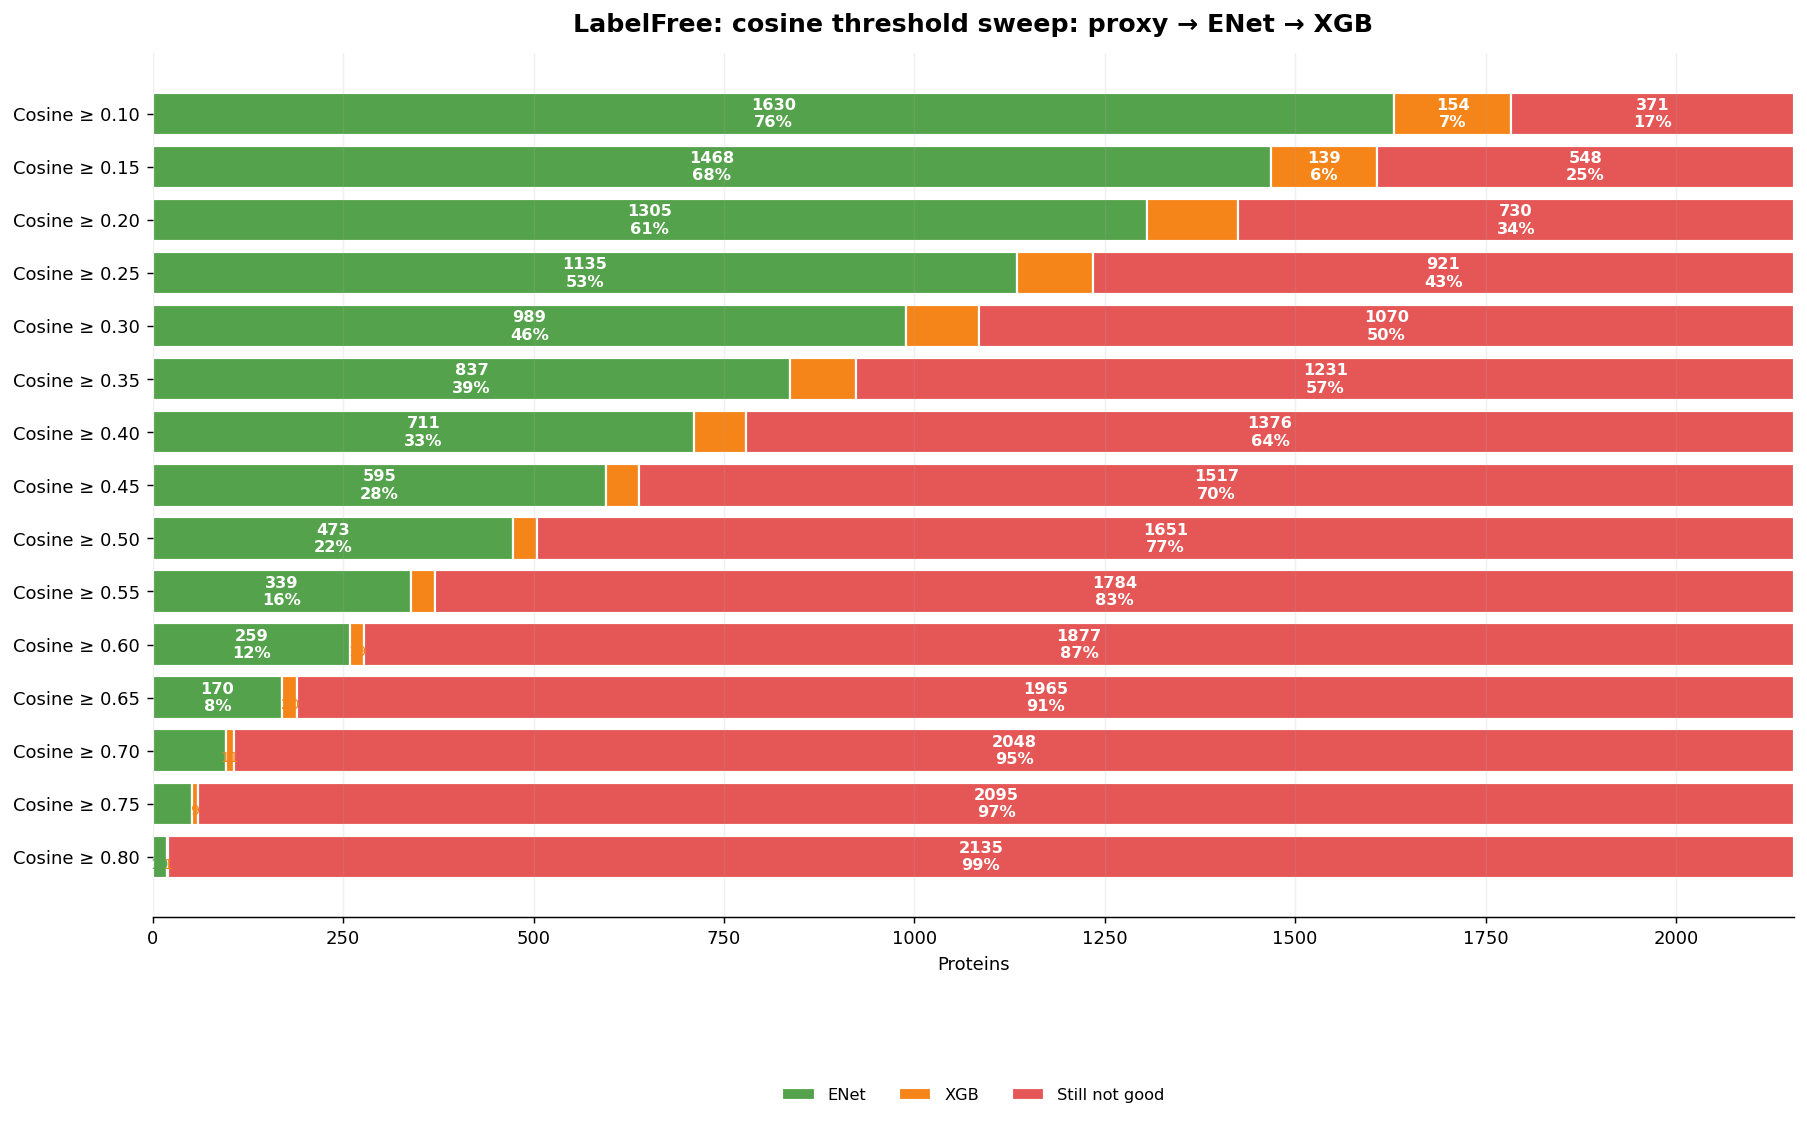

In [16]:
cosine_sweep_assignments_by_dataset = []
cosine_sweep_summaries = []

for key, tables in family_tables.items():
    dataset_name = tables["dataset_display"]
    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print("=" * 110)

    assignments = pd.concat(
        [
            procedural_metric_cascade(
                tables,
                thr,
                metric="test_cosine_similarity",
                higher=True,
                include_sc=False,
            )
            for thr in COSINE_SWEEP_THRESHOLDS
        ],
        ignore_index=True,
    )

    summary = summarize_assignments(assignments, order=CASCADE_ORDER_BASE)
    cosine_sweep_assignments_by_dataset.append(assignments)
    cosine_sweep_summaries.append(summary)

    plot_stacked_partition_rows(
        summary,
        title=f"{dataset_name}: cosine threshold sweep: proxy → ENet → XGB",
        order=CASCADE_ORDER_BASE,
        save_name=f"{key}_cosine_threshold_sweep.png",
        figsize=(14, max(5, 0.45 * len(COSINE_SWEEP_THRESHOLDS) + 2.0)),
        row_label_func=lambda thr: f"Cosine ≥ {thr:.2f}",
    )

cosine_sweep_assignments = pd.concat(cosine_sweep_assignments_by_dataset, ignore_index=True) if cosine_sweep_assignments_by_dataset else pd.DataFrame()
cosine_sweep_summary = pd.concat(cosine_sweep_summaries, ignore_index=True) if cosine_sweep_summaries else pd.DataFrame()

if SAVE_OUTPUTS:
    cosine_sweep_assignments.to_csv(EXPORT_TABLE_DIR / "cosine_threshold_sweep_assignments.csv", index=False)
    cosine_sweep_summary.to_csv(EXPORT_TABLE_DIR / "cosine_threshold_sweep_summary.csv", index=False)


## 12. Optional: load or compute scTranslator metrics

The final CCLE question asks whether scTranslator rescues proteins that proxy, ENet, and XGB did not predict well.

This section first checks whether scTranslator rows already exist in `eval_metrics_by_protein.csv`. If not, it tries to compute scTranslator `10K` metrics from saved prediction matrices, using the same alignment strategy from notebook `8.prot_model_val.ipynb`.

In [17]:
from src.utils_val import (
    clean_label_list,
    extract_labels_from_metadata,
    extract_prediction_array_from_dict,
    find_sctranslator_prediction_file,
    is_enet_zbig_zscore_k5000_label,
    load_eval_predictions_long,
    load_prediction_array,
)

In [18]:
from src.utils_val import align_sctranslator_predictions, build_enet_matrices_for_dataset, per_protein_metrics

In [19]:
sc_rows_already = metrics_partition[metrics_partition["stage"].isin(SC_STAGES)].copy()
print("Existing scTranslator metric rows:", len(sc_rows_already))

computed_sctranslator_metrics = []
sc_load_errors = []

if RUN_SCTRANSLATOR_REEVALUATION and sc_rows_already.empty:
    try:
        eval_predictions_long = load_eval_predictions_long()

        for dataset_key in DATASET_KEYS:
            print("\n" + "=" * 100)
            print(f"Attempting scTranslator {SCTRANSLATOR_VARIANT} evaluation for {dataset_key}")
            print("=" * 100)

            try:
                enet_bundle = build_enet_matrices_for_dataset(eval_predictions_long, dataset_key)
                pred_path = find_sctranslator_prediction_file(dataset_key, variant=SCTRANSLATOR_VARIANT)
                sct_array, sct_metadata = load_prediction_array(pred_path)
                y_true, enet_pred, sct_pred, proteins = align_sctranslator_predictions(
                    sct_array,
                    sct_metadata,
                    enet_bundle,
                )
                sct_metrics = per_protein_metrics(y_true, sct_pred, proteins)
                sct_metrics["dataset"] = dataset_key
                sct_metrics["dataset_key"] = normalize_name(dataset_key)
                sct_metrics["dataset_display"] = dataset_display_name(dataset_key)
                sct_metrics["run_label"] = f"scTranslator {SCTRANSLATOR_VARIANT}"
                sct_metrics["stage"] = f"scTranslator {SCTRANSLATOR_VARIANT}"
                sct_metrics["source_prediction_file"] = str(pred_path)
                computed_sctranslator_metrics.append(sct_metrics)

                print("Aligned scTranslator metrics:", sct_metrics.shape)
                display(sct_metrics.head())

            except Exception as e:
                msg = f"{dataset_key}: {type(e).__name__}: {e}"
                print("Could not evaluate scTranslator:", msg)
                sc_load_errors.append(msg)

    except Exception as e:
        msg = f"global: {type(e).__name__}: {e}"
        print("Skipping scTranslator re-evaluation:", msg)
        sc_load_errors.append(msg)

if computed_sctranslator_metrics:
    sctranslator_metrics = pd.concat(computed_sctranslator_metrics, ignore_index=True)
    metrics_partition_with_sc = pd.concat([metrics_partition, sctranslator_metrics], ignore_index=True)
else:
    sctranslator_metrics = sc_rows_already.copy()
    metrics_partition_with_sc = metrics_partition.copy()

print("Final scTranslator metric rows available:", len(metrics_partition_with_sc[metrics_partition_with_sc["stage"].isin(SC_STAGES)]))

if sc_load_errors:
    print("scTranslator load/evaluation errors:")
    for err in sc_load_errors:
        print("-", err)

if len(metrics_partition_with_sc[metrics_partition_with_sc["stage"].isin(SC_STAGES)]):
    sc_summary = (
        metrics_partition_with_sc[metrics_partition_with_sc["stage"].isin(SC_STAGES)]
        .groupby(["dataset_display", "stage", "run_label"], dropna=False)
        .agg(
            proteins=("protein", "nunique"),
            median_pearson=("test_pearson_corr", "median"),
            median_cosine=("test_cosine_similarity", "median"),
            median_mse=("test_mse", "median"),
        )
        .reset_index()
        .sort_values(["dataset_display", "stage"])
    )
    display(sc_summary)

    if SAVE_OUTPUTS:
        sc_summary.to_csv(EXPORT_TABLE_DIR / "sctranslator_summary.csv", index=False)
        sctranslator_metrics.to_csv(EXPORT_TABLE_DIR / "sctranslator_metrics_by_protein.csv", index=False)


Existing scTranslator metric rows: 0
Loading validation predictions from: ..\results_comparison_all_models\eval_predictions_long.parquet

Attempting scTranslator 10K evaluation for itraq
Aligned scTranslator metrics: (2155, 11)


,protein,n_samples,test_pearson_corr,test_cosine_similarity,test_mse,dataset,dataset_key,dataset_display,run_label,stage,source_prediction_file
0,A2M,276,-0.088803,-0.001935,0.757558,itraq,itraq,iTRAQ,scTranslator 10K,scTranslator 10K,itraq\predictions_10K.npz
1,AARS2,276,-0.186720,-0.003562,0.510638,itraq,itraq,iTRAQ,scTranslator 10K,scTranslator 10K,itraq\predictions_10K.npz
2,AASDHPPT,276,-0.179111,-0.002993,0.580199,itraq,itraq,iTRAQ,scTranslator 10K,scTranslator 10K,itraq\predictions_10K.npz
3,ABCB7,276,0.034935,0.000656,0.700974,itraq,itraq,iTRAQ,scTranslator 10K,scTranslator 10K,itraq\predictions_10K.npz
4,ABCD3,276,0.326727,0.004274,0.888946,itraq,itraq,iTRAQ,scTranslator 10K,scTranslator 10K,itraq\predictions_10K.npz



Attempting scTranslator 10K evaluation for tmt
Aligned scTranslator metrics: (2155, 11)


,protein,n_samples,test_pearson_corr,test_cosine_similarity,test_mse,dataset,dataset_key,dataset_display,run_label,stage,source_prediction_file
0,A2M,1924,-0.365775,-0.017582,5.651462,tmt,tmt,TMT,scTranslator 10K,scTranslator 10K,tmt\predictions_10K.npz
1,AARS2,1924,-0.376072,-0.014519,14.234649,tmt,tmt,TMT,scTranslator 10K,scTranslator 10K,tmt\predictions_10K.npz
2,AASDHPPT,1924,-0.355386,-0.011396,8.214811,tmt,tmt,TMT,scTranslator 10K,scTranslator 10K,tmt\predictions_10K.npz
3,ABCB7,1924,-0.189263,-0.007636,9.570338,tmt,tmt,TMT,scTranslator 10K,scTranslator 10K,tmt\predictions_10K.npz
4,ABCD3,1924,-0.411275,-0.011952,9.290902,tmt,tmt,TMT,scTranslator 10K,scTranslator 10K,tmt\predictions_10K.npz



Attempting scTranslator 10K evaluation for labelfree
Aligned scTranslator metrics: (2155, 11)


,protein,n_samples,test_pearson_corr,test_cosine_similarity,test_mse,dataset,dataset_key,dataset_display,run_label,stage,source_prediction_file
0,A2M,360,-0.195392,0.335651,0.334235,labelfree,labelfree,LabelFree,scTranslator 10K,scTranslator 10K,labelfree\predictions_10K.npz
1,AARS2,360,0.363527,-0.000241,1.723567,labelfree,labelfree,LabelFree,scTranslator 10K,scTranslator 10K,labelfree\predictions_10K.npz
2,AASDHPPT,360,0.503018,-0.002579,1.236334,labelfree,labelfree,LabelFree,scTranslator 10K,scTranslator 10K,labelfree\predictions_10K.npz
3,ABCB7,360,0.505472,0.075344,1.729083,labelfree,labelfree,LabelFree,scTranslator 10K,scTranslator 10K,labelfree\predictions_10K.npz
4,ABCD3,360,0.262745,-0.002179,0.830382,labelfree,labelfree,LabelFree,scTranslator 10K,scTranslator 10K,labelfree\predictions_10K.npz


Final scTranslator metric rows available: 6465


,dataset_display,stage,run_label,proteins,median_pearson,median_cosine,median_mse
0,LabelFree,scTranslator 10K,scTranslator 10K,2155,-0.046720,0.015962,1.081461
1,TMT,scTranslator 10K,scTranslator 10K,2155,-0.387204,-0.023396,10.759792
2,iTRAQ,scTranslator 10K,scTranslator 10K,2155,0.009668,0.000188,0.634987


## 13. Final rescue question with scTranslator

For each Pearson threshold, first run the base cascade:

```text
proxy/baseline -> ENet -> XGB
```

Then ask whether scTranslator rescues any of the remaining failures.


DATASET: iTRAQ
Final Pearson cascade with scTranslator rescue


C:\Users\hp\AppData\Local\Temp\ipykernel_16408\2151638204.py:49: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")


stage,Proxy Pearson,Proxy Spearman,Proxy baseline,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,scTranslator,Still not good after scTranslator
threshold,,,,,,,,,,
0.3,0,0,0,318,146,0,0,10,0,1681
0.5,0,0,0,24,7,0,0,0,0,2124
0.7,0,0,0,2,0,0,0,0,0,2153


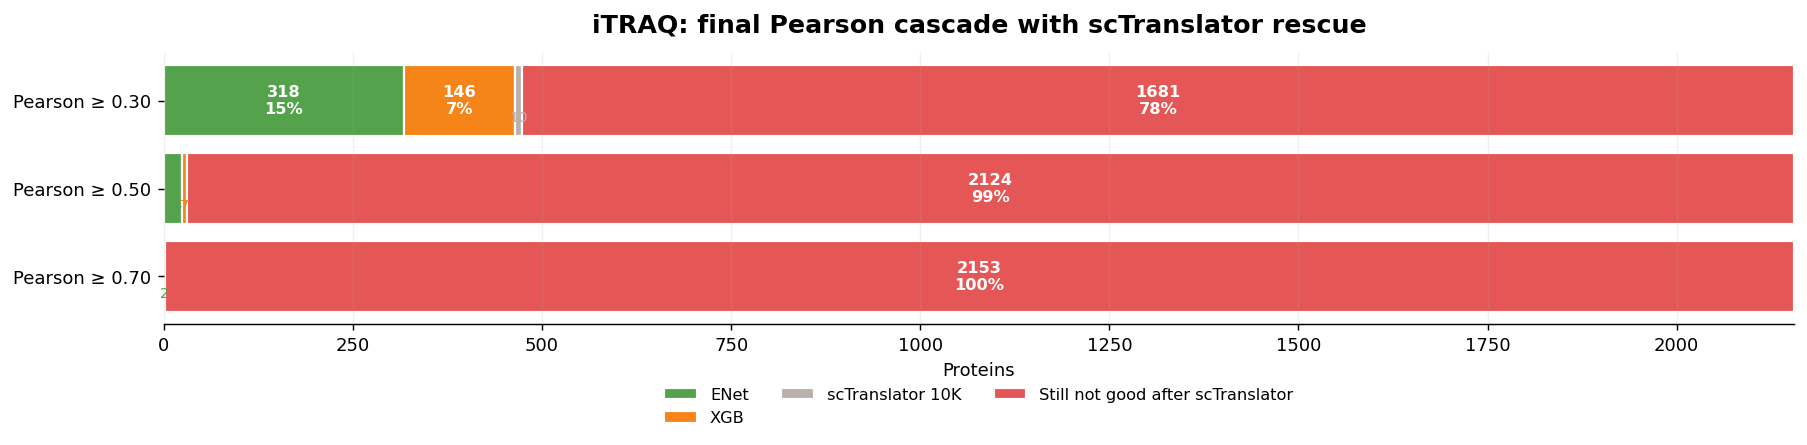


DATASET: TMT
Final Pearson cascade with scTranslator rescue


C:\Users\hp\AppData\Local\Temp\ipykernel_16408\2151638204.py:49: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")


stage,Proxy Pearson,Proxy Spearman,Proxy baseline,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,scTranslator,Still not good after scTranslator
threshold,,,,,,,,,,
0.3,0,0,0,1508,277,0,0,25,0,345
0.5,0,0,0,92,162,0,0,2,0,1899
0.7,0,0,0,2,0,0,0,0,0,2153


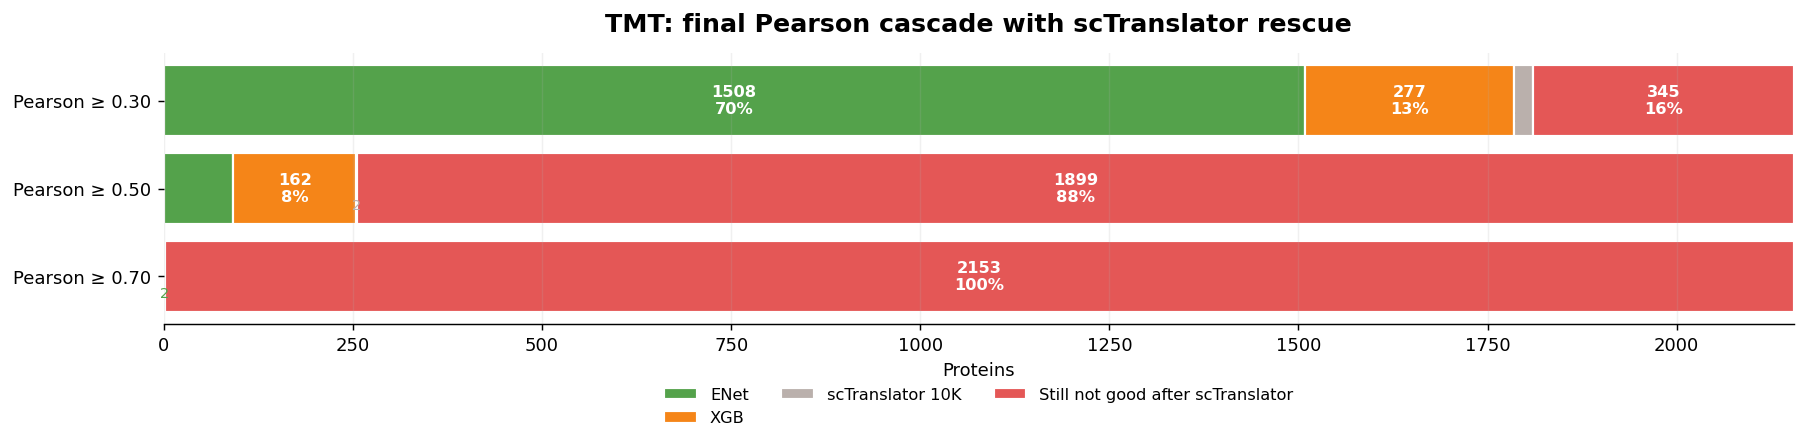


DATASET: LabelFree
Final Pearson cascade with scTranslator rescue


C:\Users\hp\AppData\Local\Temp\ipykernel_16408\2151638204.py:49: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")


stage,Proxy Pearson,Proxy Spearman,Proxy baseline,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,scTranslator,Still not good after scTranslator
threshold,,,,,,,,,,
0.3,0,0,0,1326,248,0,0,137,0,444
0.5,0,0,0,779,168,0,0,107,0,1101
0.7,0,0,0,215,63,0,0,63,0,1814


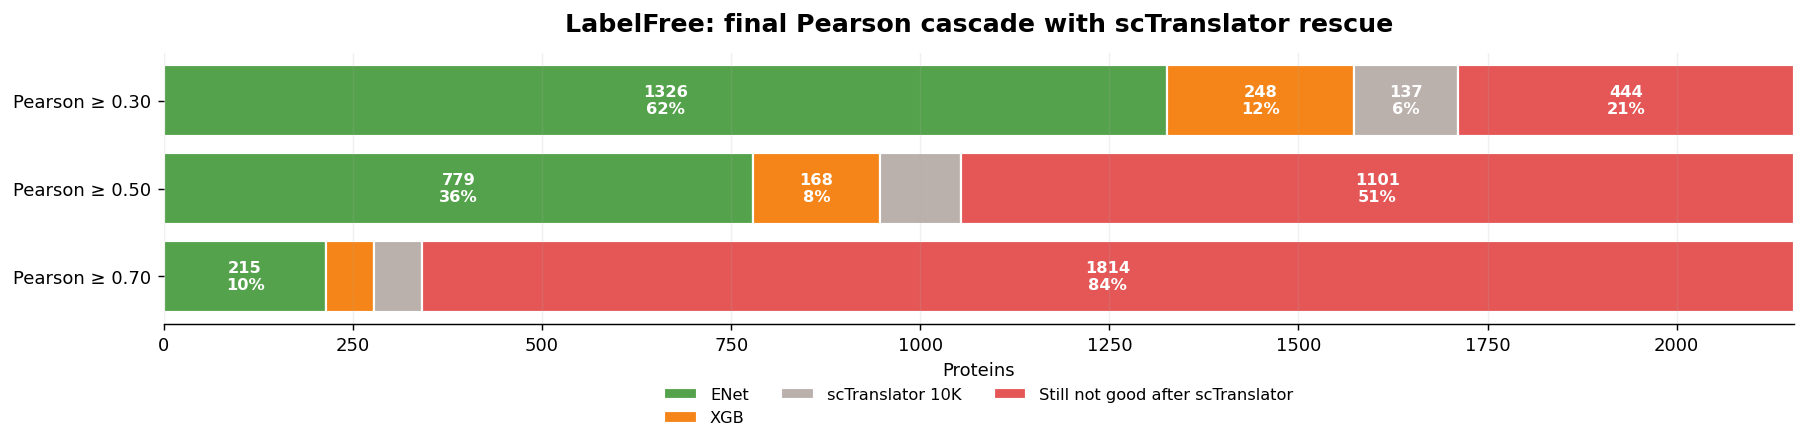

In [20]:
family_tables_with_sc = {
    key: make_family_best_tables_for_dataset(key, source_df=metrics_partition_with_sc)
    for key in DATASET_KEYS
    if len(metrics_partition_with_sc[metrics_partition_with_sc["dataset_key"].eq(key)]) > 0
}

sc_available_any = any(
    len(tables["sc_best_pearson"]) > 0
    for tables in family_tables_with_sc.values()
)

if not sc_available_any:
    print("No scTranslator metrics are available. Skipping final scTranslator rescue plots.")
else:
    final_sc_assignments_by_dataset = []
    final_sc_summaries = []

    for key, tables in family_tables_with_sc.items():
        dataset_name = tables["dataset_display"]
        if len(tables["sc_best_pearson"]) == 0:
            print(f"No scTranslator rows for {dataset_name}; skipping.")
            continue

        print("\n" + "=" * 110)
        print(f"DATASET: {dataset_name}")
        print("=" * 110)

        assignments = pd.concat(
            [
                procedural_metric_cascade(
                    tables,
                    thr,
                    metric="test_pearson_corr",
                    higher=True,
                    include_sc=True,
                )
                for thr in PEARSON_GOOD_THRESHOLDS
            ],
            ignore_index=True,
        )

        summary = summarize_assignments(assignments, order=CASCADE_ORDER_WITH_SC)
        final_sc_assignments_by_dataset.append(assignments)
        final_sc_summaries.append(summary)

        print("Final Pearson cascade with scTranslator rescue")
        display(
            summary
            .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
            .reindex(columns=CASCADE_ORDER_WITH_SC)
        )

        plot_stacked_partition_rows(
            summary,
            title=f"{dataset_name}: final Pearson cascade with scTranslator rescue",
            order=CASCADE_ORDER_WITH_SC,
            save_name=f"{key}_pearson_cascade_with_sctranslator.png",
            row_label_func=lambda thr: f"Pearson ≥ {thr:.2f}",
        )

    final_sc_assignments = pd.concat(final_sc_assignments_by_dataset, ignore_index=True) if final_sc_assignments_by_dataset else pd.DataFrame()
    final_sc_summary = pd.concat(final_sc_summaries, ignore_index=True) if final_sc_summaries else pd.DataFrame()

    if SAVE_OUTPUTS and len(final_sc_assignments):
        final_sc_assignments.to_csv(EXPORT_TABLE_DIR / "final_sctranslator_rescue_assignments.csv", index=False)
        final_sc_summary.to_csv(EXPORT_TABLE_DIR / "final_sctranslator_rescue_summary.csv", index=False)


## 14. Tissue-level validation summary

This section is inherited from notebook 8 and is useful context for the validation datasets. It reports which run wins at tissue level by Pearson, if tissue-level metrics are available.

Tissue-level metric rows: 108

 iTRAQ best tissue-level Pearson winners


,tissue,run_label,stage,test_pearson_corr,n_samples,n_proteins
31,breast,res_xgb_zbig | zscore | current | k5000,XGB,0.054409,77,2155
50,ovary,results_xgb | none | fast | k2000,XGB,0.022427,119,2155
15,stomach,res_enet_zbig | zscore | fast | k5000,ENet,0.010894,80,2155


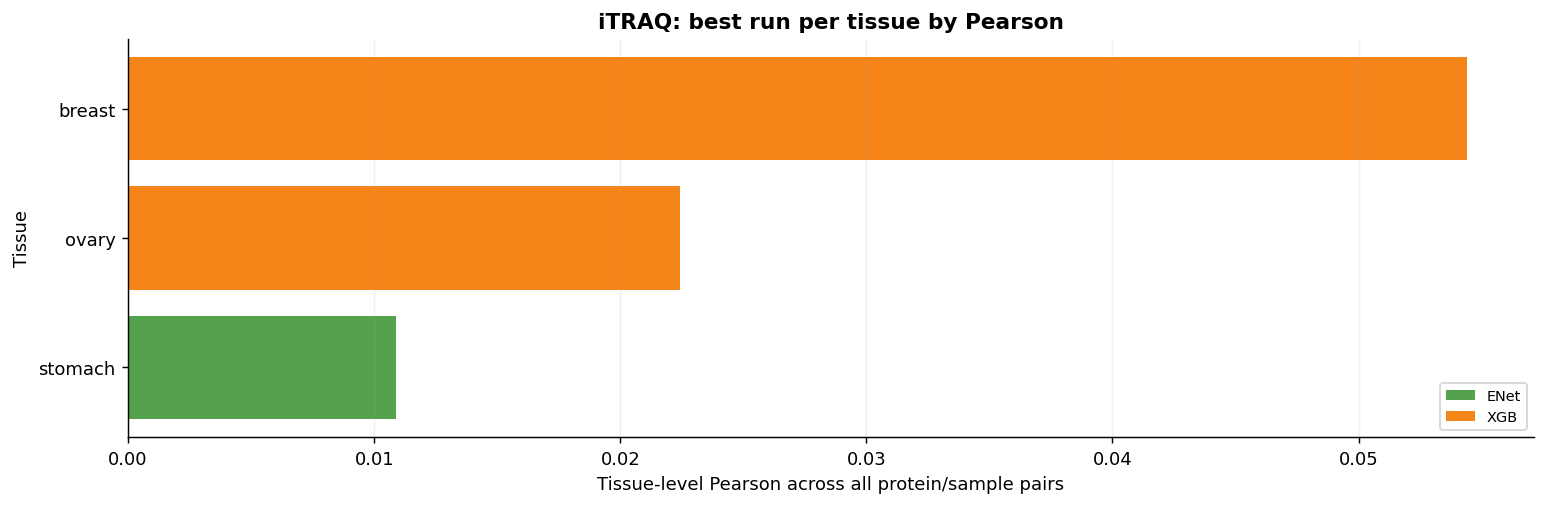


 LabelFree best tissue-level Pearson winners


,tissue,run_label,stage,test_pearson_corr,n_samples,n_proteins
127,brain,results_xgb | zscore | fast | k2000,XGB,0.141382,71,2155
75,liver,results_xgb | qbin50 | fast | k2000,XGB,0.093916,62,2155
126,colon,results_xgb | zscore | fast | k2000,XGB,0.090950,86,2155
74,prostate,results_xgb | qbin50 | fast | k2000,XGB,0.068070,65,2155
22,lung,res_xgb_zbig | zscore | current | k5000,XGB,0.059481,76,2155


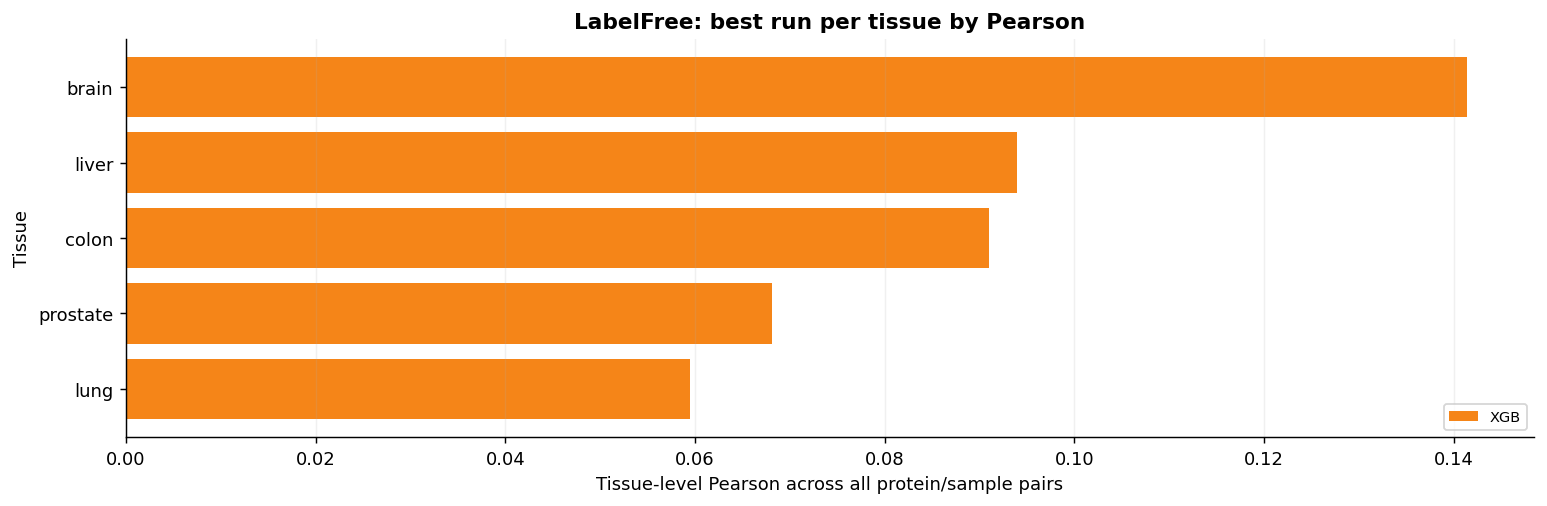


 TMT best tissue-level Pearson winners


,tissue,run_label,stage,test_pearson_corr,n_samples,n_proteins
46,headneck,results_xgb | none | fast | k2000,XGB,0.454921,151,2155
43,renal,results_xgb | none | fast | k2000,XGB,0.444998,185,2155
47,pancrea,results_xgb | none | fast | k2000,XGB,0.414931,140,2155
30,brain,res_xgb_zbig | zscore | current | k5000,XGB,0.227846,108,2155
35,unknown,res_xgb_zbig | zscore | current | k5000,XGB,0.221154,115,2155
23,liver,res_xgb_zbig | zscore | current | k5000,XGB,0.142236,318,2155
24,colon,res_xgb_zbig | zscore | current | k5000,XGB,0.046795,95,2155
9,breast,res_enet_zbig | zscore | fast | k5000,ENet,-0.044246,122,2155
16,lung,res_enet_zbig | zscore | fast | k5000,ENet,-0.048479,502,2155
8,pedbrain,res_enet_zbig | zscore | fast | k5000,ENet,-0.150233,188,2155


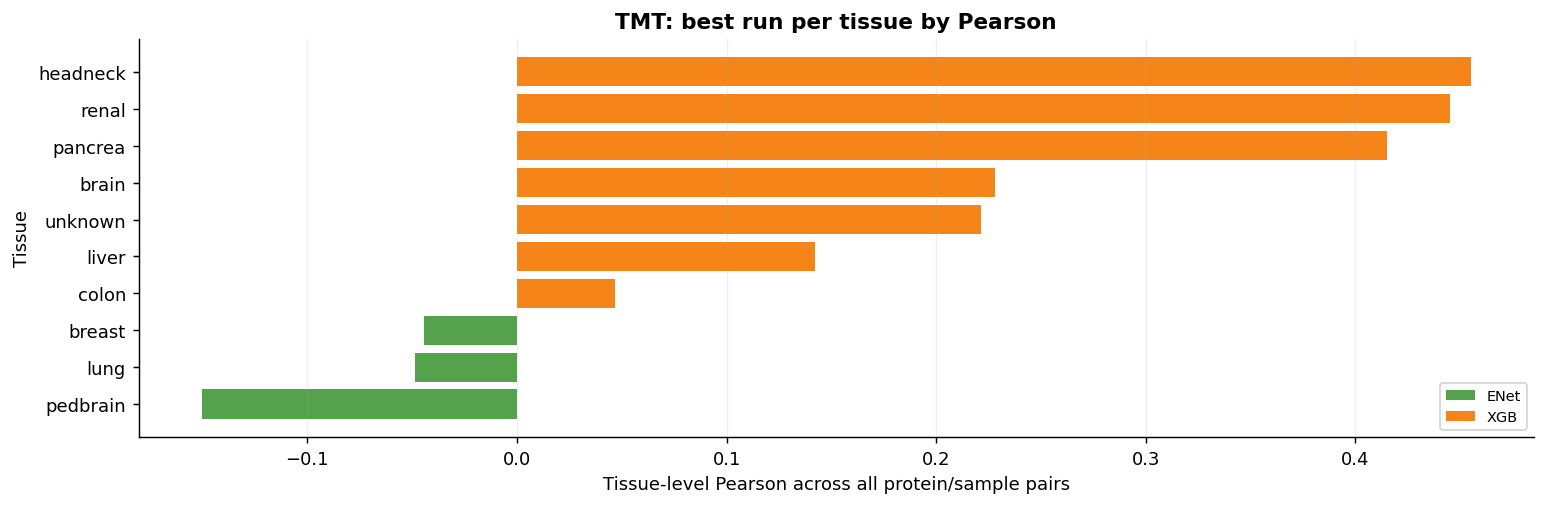

In [21]:
if metrics_by_tissue.empty:
    print("No tissue-level metrics were found.")
else:
    tissue = metrics_by_tissue.copy()
    tissue["dataset_key"] = tissue["dataset"].map(normalize_name)
    tissue = tissue[tissue["dataset_key"].isin(DATASET_KEYS)].copy()
    tissue = tissue[
        ~tissue["run_label"].astype(str).str.contains(SKIP_K_PATTERN, case=False, regex=True, na=False)
    ].copy()
    tissue["stage"] = tissue["run_label"].map(infer_stage_from_run_label)
    tissue["dataset_display"] = tissue["dataset_key"].map(dataset_display_name)

    print("Tissue-level metric rows:", len(tissue))

    for dataset_key in sorted(tissue["dataset_key"].dropna().unique()):
        dataset_name = dataset_display_name(dataset_key)
        sub = tissue[tissue["dataset_key"].eq(dataset_key)].copy()
        if sub.empty:
            continue

        best_tissue_pearson = (
            sub.dropna(subset=["test_pearson_corr"])
            .sort_values(["tissue", "test_pearson_corr"], ascending=[True, False])
            .groupby("tissue", as_index=False)
            .head(1)
        )

        print("\n", dataset_name, "best tissue-level Pearson winners")
        cols = [c for c in ["tissue", "run_label", "stage", "test_pearson_corr", "n_samples", "n_proteins"] if c in best_tissue_pearson.columns]
        display(best_tissue_pearson[cols].sort_values("test_pearson_corr", ascending=False).head(30))

        if len(best_tissue_pearson):
            plot_data = best_tissue_pearson.sort_values("test_pearson_corr", ascending=True).tail(25)
            fig, ax = plt.subplots(figsize=(12, max(4, 0.35 * plot_data["tissue"].nunique())))
            for stage, sub_stage in plot_data.groupby("stage", sort=False):
                ax.barh(sub_stage["tissue"], sub_stage["test_pearson_corr"], label=stage, color=COLOR_MAP.get(stage, None))
            ax.set_title(f"{dataset_name}: best run per tissue by Pearson")
            ax.set_xlabel("Tissue-level Pearson across all protein/sample pairs")
            ax.set_ylabel("Tissue")
            ax.legend(loc="lower right", fontsize=8, frameon=True)
            ax.grid(axis="x", alpha=0.18)
            plt.tight_layout()
            if SAVE_OUTPUTS:
                fig.savefig(FIGURE_DIR / f"{dataset_key}_best_tissue_pearson.png", dpi=180, bbox_inches="tight")
            plt.show()


## 15. Optional final exports

When `SAVE_OUTPUTS = True`, earlier cells write the main tables as they are created. This cell also saves a compact manifest of generated outputs.

In [22]:
if SAVE_OUTPUTS:
    manifest = {
        "output_dir": str(OUTPUT_DIR),
        "table_dir": str(EXPORT_TABLE_DIR),
        "figure_dir": str(FIGURE_DIR),
        "requested_datasets": REQUESTED_DATASETS,
        "pearson_good_thresholds": PEARSON_GOOD_THRESHOLDS,
        "pearson_sweep_thresholds": PEARSON_SWEEP_THRESHOLDS,
        "mse_sweep_thresholds": MSE_SWEEP_THRESHOLDS,
        "mse_percentile_thresholds": MSE_PERCENTILE_THRESHOLDS,
        "cosine_sweep_thresholds": COSINE_SWEEP_THRESHOLDS,
        "sctranslator_variant": SCTRANSLATOR_VARIANT,
    }
    with open(EXPORT_TABLE_DIR / "procedural_cptac_manifest.json", "w") as f:
        json.dump(manifest, f, indent=2)

    print("Saved tables to:", EXPORT_TABLE_DIR)
    print("Saved figures to:", FIGURE_DIR)
else:
    print("SAVE_OUTPUTS is False. Set it to True in the configuration cell to export tables and figures.")


SAVE_OUTPUTS is False. Set it to True in the configuration cell to export tables and figures.


In [ ]:
# from src.utils_val import (
#     _fmt_float,
#     _get_global,
#     _safe_name,
#     _standardize_assignment_table,
#     _threshold_label,
#     _valid_df,
# )

# # =====================================================================
# # Export protein names by cascade/partition threshold and model/stage
# #
# # Works in:
# #   - procedural_ccle.ipynb
# #   - 9.procedural_cptac.ipynb
# #
# # What it saves:
# #   1. cascade_partition_proteins_long.csv
# #      one protein per row
# #
# #   2. cascade_partition_proteins_grouped.csv
# #      one row per dataset / analysis / threshold / stage,
# #      with all protein names joined into one field
# #
# #   3. cascade_partition_proteins_files_manifest.csv
# #      index of all separate files
# #
# #   4. protein_lists_one_file_per_partition/
# #      one separate CSV for each threshold + cascade stage/model
# # =====================================================================

# from pathlib import Path
# import pandas as pd
# import numpy as np
# import re
# import hashlib

# SAVE_CASCADE_PROTEIN_EXPORTS = True

# # ---------------------------------------------------------------------
# # Output folders
# # ---------------------------------------------------------------------

# try:
#     EXPORT_TABLE_DIR
# except NameError:
#     EXPORT_TABLE_DIR = Path("procedural_tables")

# EXPORT_TABLE_DIR = Path(EXPORT_TABLE_DIR)
# EXPORT_TABLE_DIR.mkdir(parents=True, exist_ok=True)

# PROTEIN_EXPORT_DIR = EXPORT_TABLE_DIR / "protein_names_by_cascade_partition"
# PROTEIN_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# SPLIT_EXPORT_DIR = PROTEIN_EXPORT_DIR / "protein_lists_one_file_per_partition"
# SPLIT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)


# # ---------------------------------------------------------------------
# # Helpers
# # ---------------------------------------------------------------------













# # ---------------------------------------------------------------------
# # Detect notebook type and collect available assignment tables
# # ---------------------------------------------------------------------

# is_cptac = (
#     _valid_df(_get_global("main_pearson_assignments"))
#     or _valid_df(_get_global("pearson_sweep_assignments"))
#     or _valid_df(_get_global("mse_percentile_assignments"))
#     or _valid_df(_get_global("final_sc_assignments"))
# )

# if is_cptac:
#     default_dataset = "CPTAC"

#     candidate_tables = [
#         ("main_pearson_cascade", "main_pearson_assignments", _get_global("main_pearson_assignments")),
#         ("pearson_threshold_sweep", "pearson_sweep_assignments", _get_global("pearson_sweep_assignments")),
#         ("proxy_correlation_threshold_sweep", "proxy_corr_assignments", _get_global("proxy_corr_assignments")),
#         ("mse_threshold_sweep", "mse_sweep_assignments", _get_global("mse_sweep_assignments")),
#         ("mse_percentile_threshold_sweep", "mse_percentile_assignments", _get_global("mse_percentile_assignments")),
#         ("mse_winner_partition", "mse_winner", _get_global("mse_winner")),
#         ("mse_procedural_improvement_partition", "mse_improvement", _get_global("mse_improvement")),
#         ("cosine_threshold_sweep", "cosine_sweep_assignments", _get_global("cosine_sweep_assignments")),
#         ("pearson_cascade_with_sctranslator", "final_sc_assignments", _get_global("final_sc_assignments")),
#     ]

# else:
#     default_dataset = "CCLE"

#     candidate_tables = [
#         ("main_pearson_cascade", "main_assignments", _get_global("main_assignments")),
#         ("pearson_threshold_sweep", "sweep_assignments", _get_global("sweep_assignments")),
#         ("proxy_correlation_threshold_sweep", "proxy_corr_assignments", _get_global("proxy_corr_assignments")),
#         ("mse_threshold_sweep", "mse_sweep_assignments", _get_global("mse_sweep_assignments")),
#         ("mse_winner_partition", "mse_winner", _get_global("mse_winner")),
#         ("mse_procedural_improvement_partition", "mse_improvement", _get_global("mse_improvement")),
#         ("pearson_cascade_with_sctranslator", "sc_assignments", _get_global("sc_assignments")),
#         ("sctranslator_rescue_only", "sc_rescue_only", _get_global("sc_rescue_only")),
#     ]


# standardized_tables = []

# for analysis_name, source_variable, df in candidate_tables:
#     if not _valid_df(df):
#         print(f"Skipped missing or empty table: {source_variable}")
#         continue

#     tmp = _standardize_assignment_table(
#         df=df,
#         analysis_name=analysis_name,
#         source_variable=source_variable,
#         default_dataset=default_dataset,
#     )

#     if _valid_df(tmp):
#         standardized_tables.append(tmp)
#         print(
#             f"Included: {source_variable} -> {analysis_name} "
#             f"({len(tmp):,} protein rows)"
#         )

# if len(standardized_tables) == 0:
#     raise ValueError(
#         "No assignment tables were found. "
#         "Run the cascade/sweep plotting cells first, then rerun this export cell."
#     )


# # ---------------------------------------------------------------------
# # Long protein-level table
# # ---------------------------------------------------------------------

# cascade_partition_proteins_long = pd.concat(
#     standardized_tables,
#     ignore_index=True,
# )

# cascade_partition_proteins_long = (
#     cascade_partition_proteins_long
#     .sort_values(
#         [
#             "dataset",
#             "analysis",
#             "threshold_label",
#             "stage",
#             "protein",
#         ]
#     )
#     .reset_index(drop=True)
# )


# # ---------------------------------------------------------------------
# # Grouped readable table: one row per graph segment
# # ---------------------------------------------------------------------

# group_cols = [
#     "dataset",
#     "analysis",
#     "source_variable",
#     "threshold_label",
#     "stage",
# ]

# cascade_partition_proteins_grouped = (
#     cascade_partition_proteins_long
#     .groupby(group_cols, dropna=False)
#     .agg(
#         n_proteins=("protein", "nunique"),
#         protein_names=("protein", lambda x: "; ".join(sorted(set(map(str, x))))),
#     )
#     .reset_index()
#     .sort_values(group_cols)
#     .reset_index(drop=True)
# )

# cascade_partition_proteins_grouped["protein_names_preview"] = (
#     cascade_partition_proteins_grouped["protein_names"]
#     .str.split("; ")
#     .apply(lambda xs: "; ".join(xs[:25]) + ("; ..." if len(xs) > 25 else ""))
# )


# # ---------------------------------------------------------------------
# # One file per dataset / analysis / threshold / stage
# # ---------------------------------------------------------------------

# manifest_rows = []
# split_tables = []

# for keys, sub in cascade_partition_proteins_long.groupby(group_cols, dropna=False):
#     info = dict(zip(group_cols, keys))

#     file_stem = "__".join(
#         [
#             _safe_name(info["dataset"]),
#             _safe_name(info["analysis"]),
#             _safe_name(info["threshold_label"]),
#             _safe_name(info["stage"]),
#         ]
#     )

#     file_name = f"{file_stem}.csv"
#     out_path = SPLIT_EXPORT_DIR / file_name

#     keep_cols = [
#         c for c in [
#             "dataset",
#             "analysis",
#             "source_variable",
#             "threshold_label",
#             "stage",
#             "protein",
#             "threshold",
#             "prediction_threshold",
#             "corr_threshold",
#             "mse_percentile_threshold",
#             "metric",
#             "test_pearson_corr",
#             "test_mse",
#             "test_cosine_similarity",
#             "best_mse",
#             "proxy_mse",
#             "enet_mse",
#             "xgb_mse",
#             "same_gene_corr_full",
#             "proxy_corr",
#             "run_label",
#             "model_name",
#             "proxy_type",
#         ]
#         if c in sub.columns
#     ]

#     split_df = (
#         sub[keep_cols]
#         .drop_duplicates()
#         .sort_values("protein")
#         .reset_index(drop=True)
#     )

#     split_tables.append((out_path, split_df))

#     manifest_rows.append(
#         {
#             "dataset": info["dataset"],
#             "analysis": info["analysis"],
#             "source_variable": info["source_variable"],
#             "threshold_label": info["threshold_label"],
#             "stage": info["stage"],
#             "n_proteins": split_df["protein"].nunique(),
#             "file_name": file_name,
#             "relative_path": str(out_path.relative_to(PROTEIN_EXPORT_DIR)),
#         }
#     )

# cascade_partition_proteins_manifest = (
#     pd.DataFrame(manifest_rows)
#     .sort_values(
#         [
#             "dataset",
#             "analysis",
#             "threshold_label",
#             "stage",
#         ]
#     )
#     .reset_index(drop=True)
# )


# # ---------------------------------------------------------------------
# # Display BEFORE saving
# # ---------------------------------------------------------------------

# print("\nGrouped table to be saved:")
# display(
#     cascade_partition_proteins_grouped[
#         [
#             "dataset",
#             "analysis",
#             "source_variable",
#             "threshold_label",
#             "stage",
#             "n_proteins",
#             "protein_names_preview",
#         ]
#     ]
# )

# print("\nLong protein-level table to be saved, first 100 rows:")
# display(cascade_partition_proteins_long.head(100))

# print("\nManifest of one-file-per-partition exports to be saved:")
# display(cascade_partition_proteins_manifest)


# # ---------------------------------------------------------------------
# # Save
# # ---------------------------------------------------------------------

# if SAVE_CASCADE_PROTEIN_EXPORTS:
#     long_path = PROTEIN_EXPORT_DIR / "cascade_partition_proteins_long.csv"
#     grouped_path = PROTEIN_EXPORT_DIR / "cascade_partition_proteins_grouped.csv"
#     manifest_path = PROTEIN_EXPORT_DIR / "cascade_partition_proteins_files_manifest.csv"

#     cascade_partition_proteins_long.to_csv(long_path, index=False)
#     cascade_partition_proteins_grouped.to_csv(grouped_path, index=False)
#     cascade_partition_proteins_manifest.to_csv(manifest_path, index=False)

#     for out_path, split_df in split_tables:
#         split_df.to_csv(out_path, index=False)

#     print("\nSaved protein partition exports:")
#     print("Long protein-level table:", long_path)
#     print("Grouped protein-name table:", grouped_path)
#     print("Manifest:", manifest_path)
#     print("One file per threshold/stage:", SPLIT_EXPORT_DIR)
# else:
#     print("SAVE_CASCADE_PROTEIN_EXPORTS is False, so nothing was saved.")

Skipped missing or empty table: main_assignments
Skipped missing or empty table: sweep_assignments
Skipped missing or empty table: proxy_corr_assignments
Skipped missing or empty table: mse_sweep_assignments
Skipped missing or empty table: mse_winner
Skipped missing or empty table: mse_improvement
Skipped missing or empty table: sc_assignments
Skipped missing or empty table: sc_rescue_only


ValueError: No assignment tables were found. Run the cascade/sweep plotting cells first, then rerun this export cell.